# Lista 2 - Estatística Bayesiana

## Configuração do ambiente

In [102]:
# Bibliotecas e ajustes dos gráficos
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from matplotlib.lines import Line2D
from scipy.integrate import quad
from scipy.optimize import minimize_scalar
from scipy.special import erf, erfinv, gamma, comb
from scipy.stats import beta, beta as beta_dist

sns.set_theme(context='notebook', style='white', palette='deep',
              rc={'figure.dpi': 500})
mpl.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman'],
    'font.size': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 15,
    'axes.titlesize': 15,
    'axes.unicode_minus': False,
})

colors = ['lightblue', 'lightgreen', 'lightsalmon', 'plum', 'khaki']

## Exercício 1 — Aproximação Gaussiana e quantis

### (a) Distribuição aproximada e quantis

In [103]:
x = np.linspace(0, 1000, 1000)

quantiles = [0.05, 0.25, 0.50, 0.75, 0.95]

def normal_dist(x, sigma, mu): 
    return 1/(np.sqrt(2*np.pi)*sigma) * np.exp(-((x-mu)**2/(2*sigma**2)))

def y_variable(a, sigma, mu):
    z = np.sqrt(2) * erfinv(2*a - 1)
    return sigma*z + mu

In [104]:
gaussian_1a = normal_dist(x, np.sqrt(1000*(1/6)*(5/6)), 1000/6)

for i in quantiles:
    y_1a = y_variable(i, np.sqrt(1000*(1/6)*(5/6)), 1000/6)
    print(f'p(y < {y_1a:.2f}) = {i:.2f}')

p(y < 147.28) = 0.05
p(y < 158.72) = 0.25
p(y < 166.67) = 0.50
p(y < 174.62) = 0.75
p(y < 186.05) = 0.95


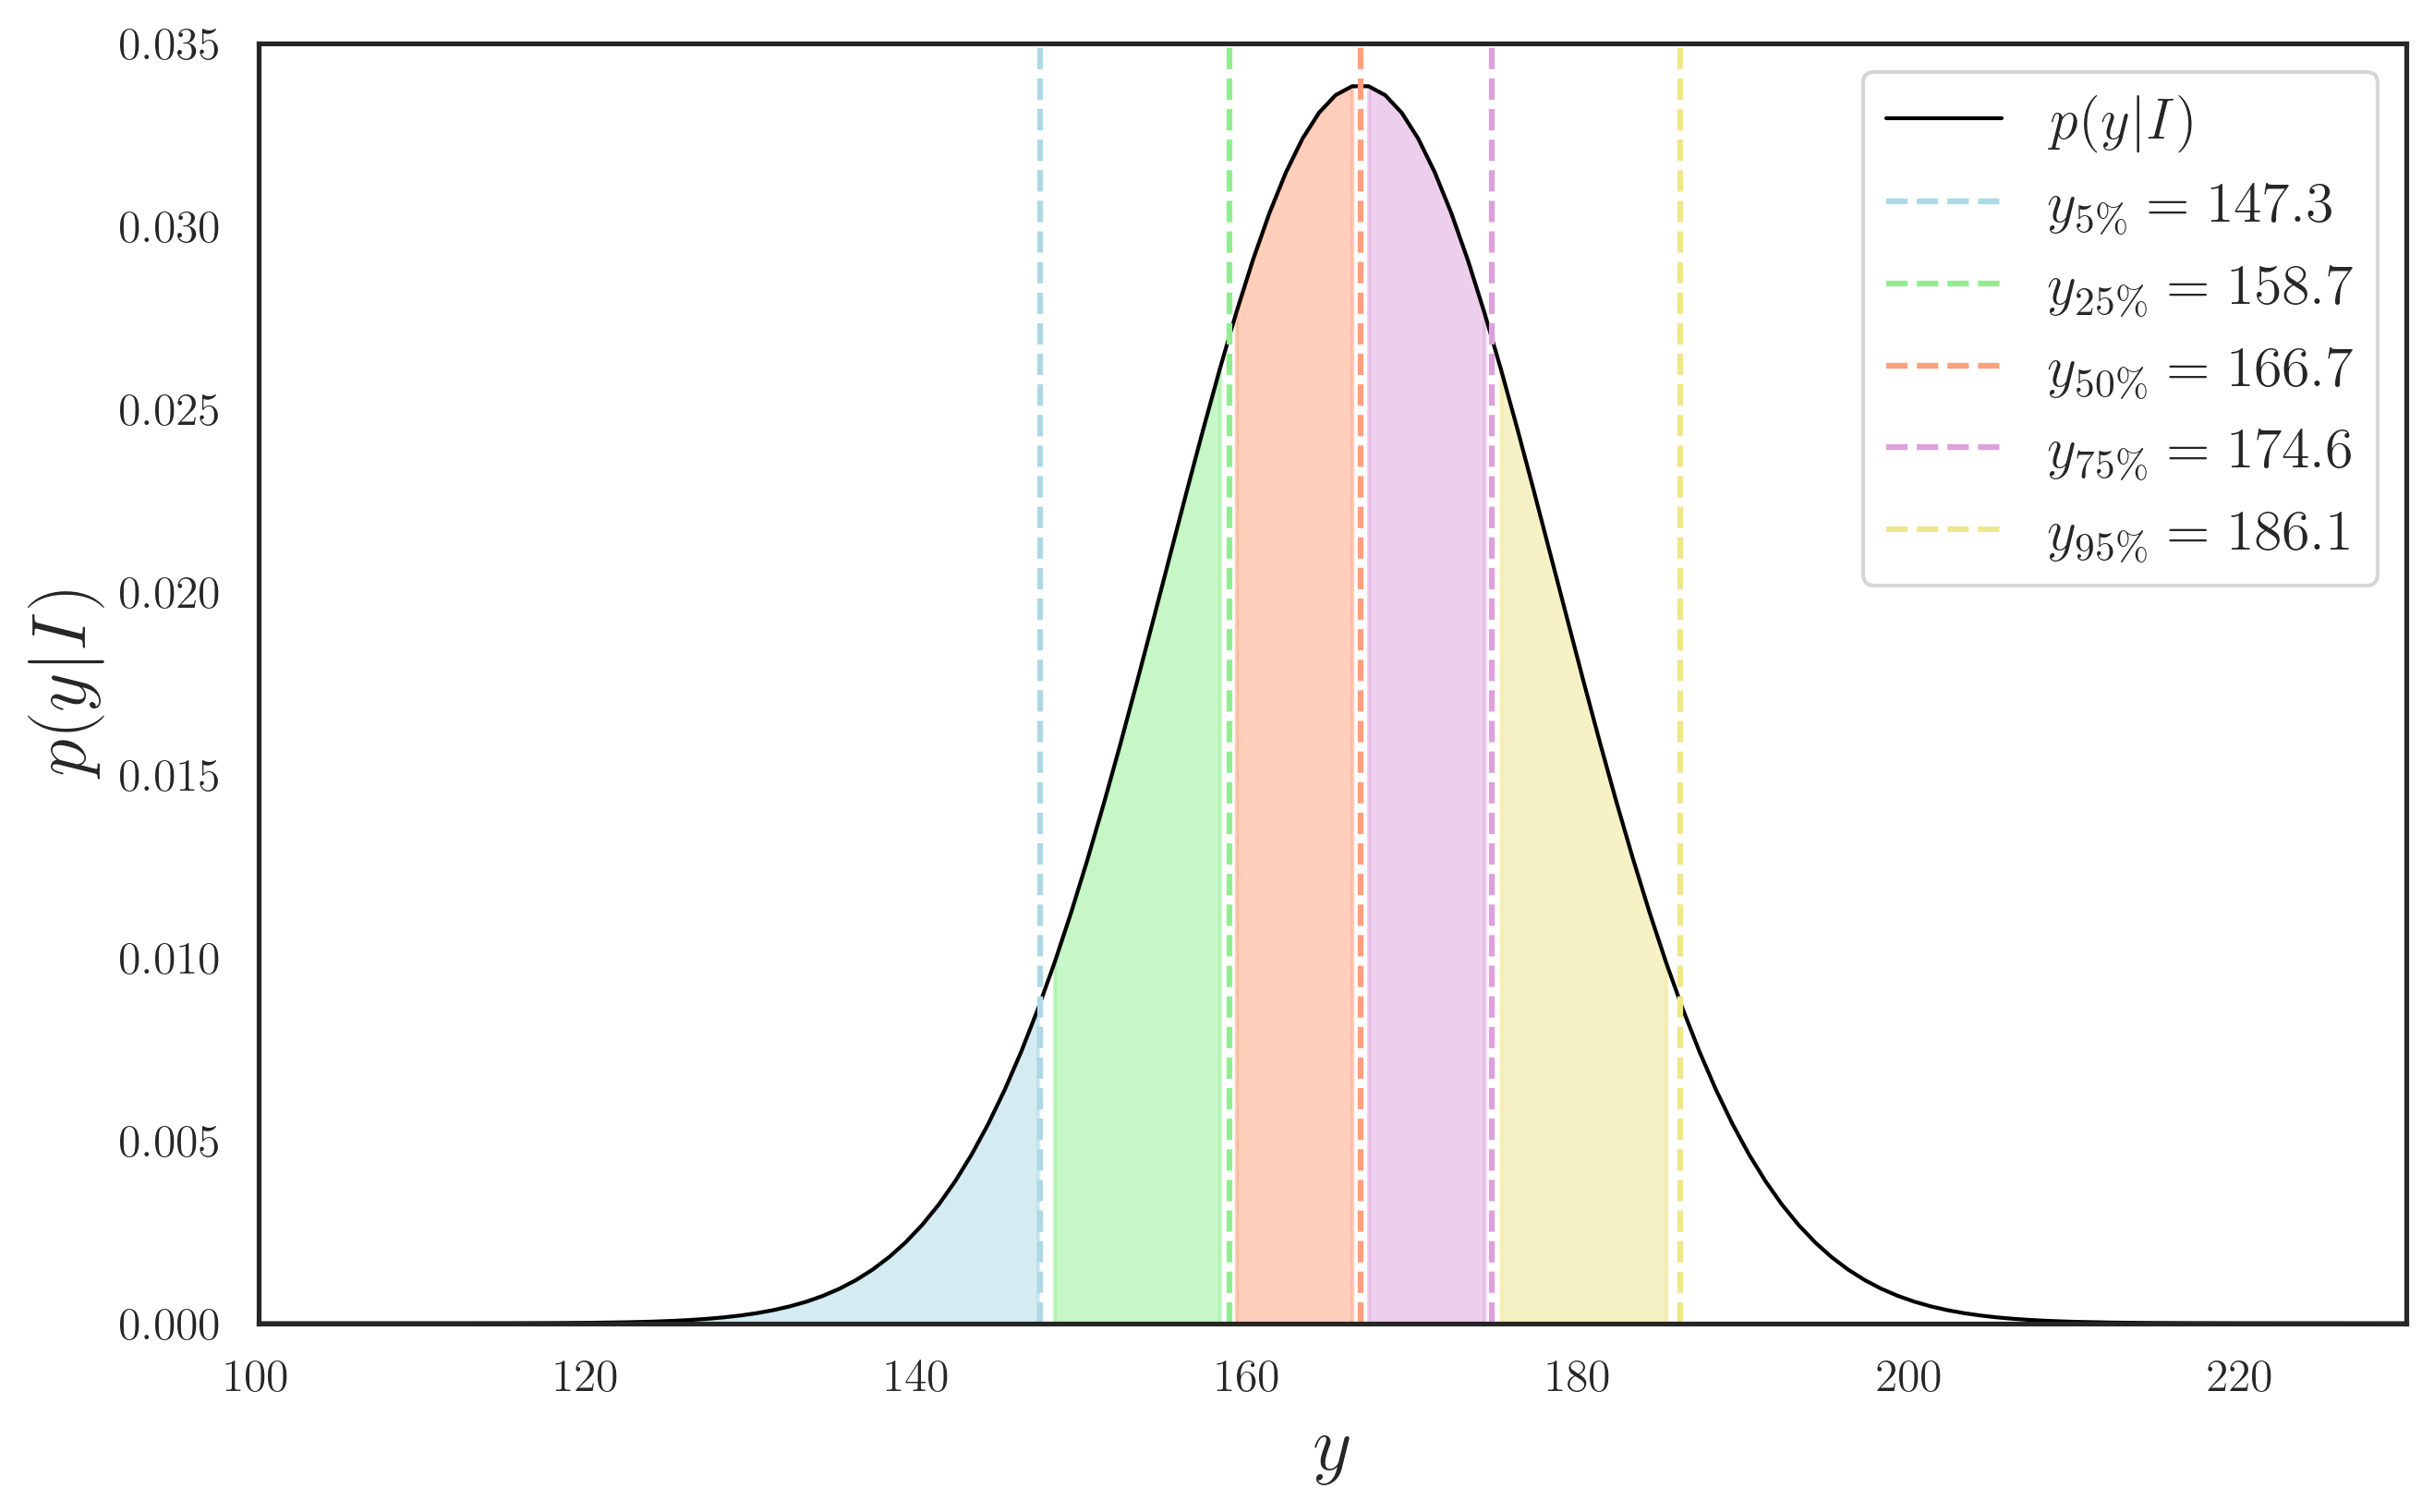

In [105]:
plt.figure(figsize=(10, 6), dpi=300)

plt.plot(x, gaussian_1a, color='black', lw=1.0, label=r'$p(y|I)$')

y_quantiles = [y_variable(q, np.sqrt(1000*(1/6)*(5/6)), 1000/6) for q in quantiles]

previous_y = x.min()

for q, y, color in zip(quantiles, y_quantiles, colors):

    plt.fill_between(x, gaussian_1a, where=(x >= previous_y) & (x <= y), alpha=0.5, color=color)

    plt.axvline(y, ls='--', color=color, lw=1.5, label=fr'$y_{{{100*q:.0f}\%}} = {y:.1f}$')

    previous_y = y

plt.xlabel(r'$y$')
plt.ylabel(r'$p(y|I)$')
plt.xlim(100, 230)
plt.ylim(0, 0.035)
plt.legend(fontsize=15)

plt.show()

### (b) Composição de distribuições

In [106]:
thetas = [1/8, 1/6, 1/4]
weights = [0.3, 0.5, 0.2]


labels = [r'$\theta = 1/8$', r'$\theta = 1/6$', r'$\theta = 1/4$']

mu = np.array([1000 * theta for theta in thetas])

sigma = np.array([np.sqrt(1000 * theta * (1 - theta)) for theta in thetas])

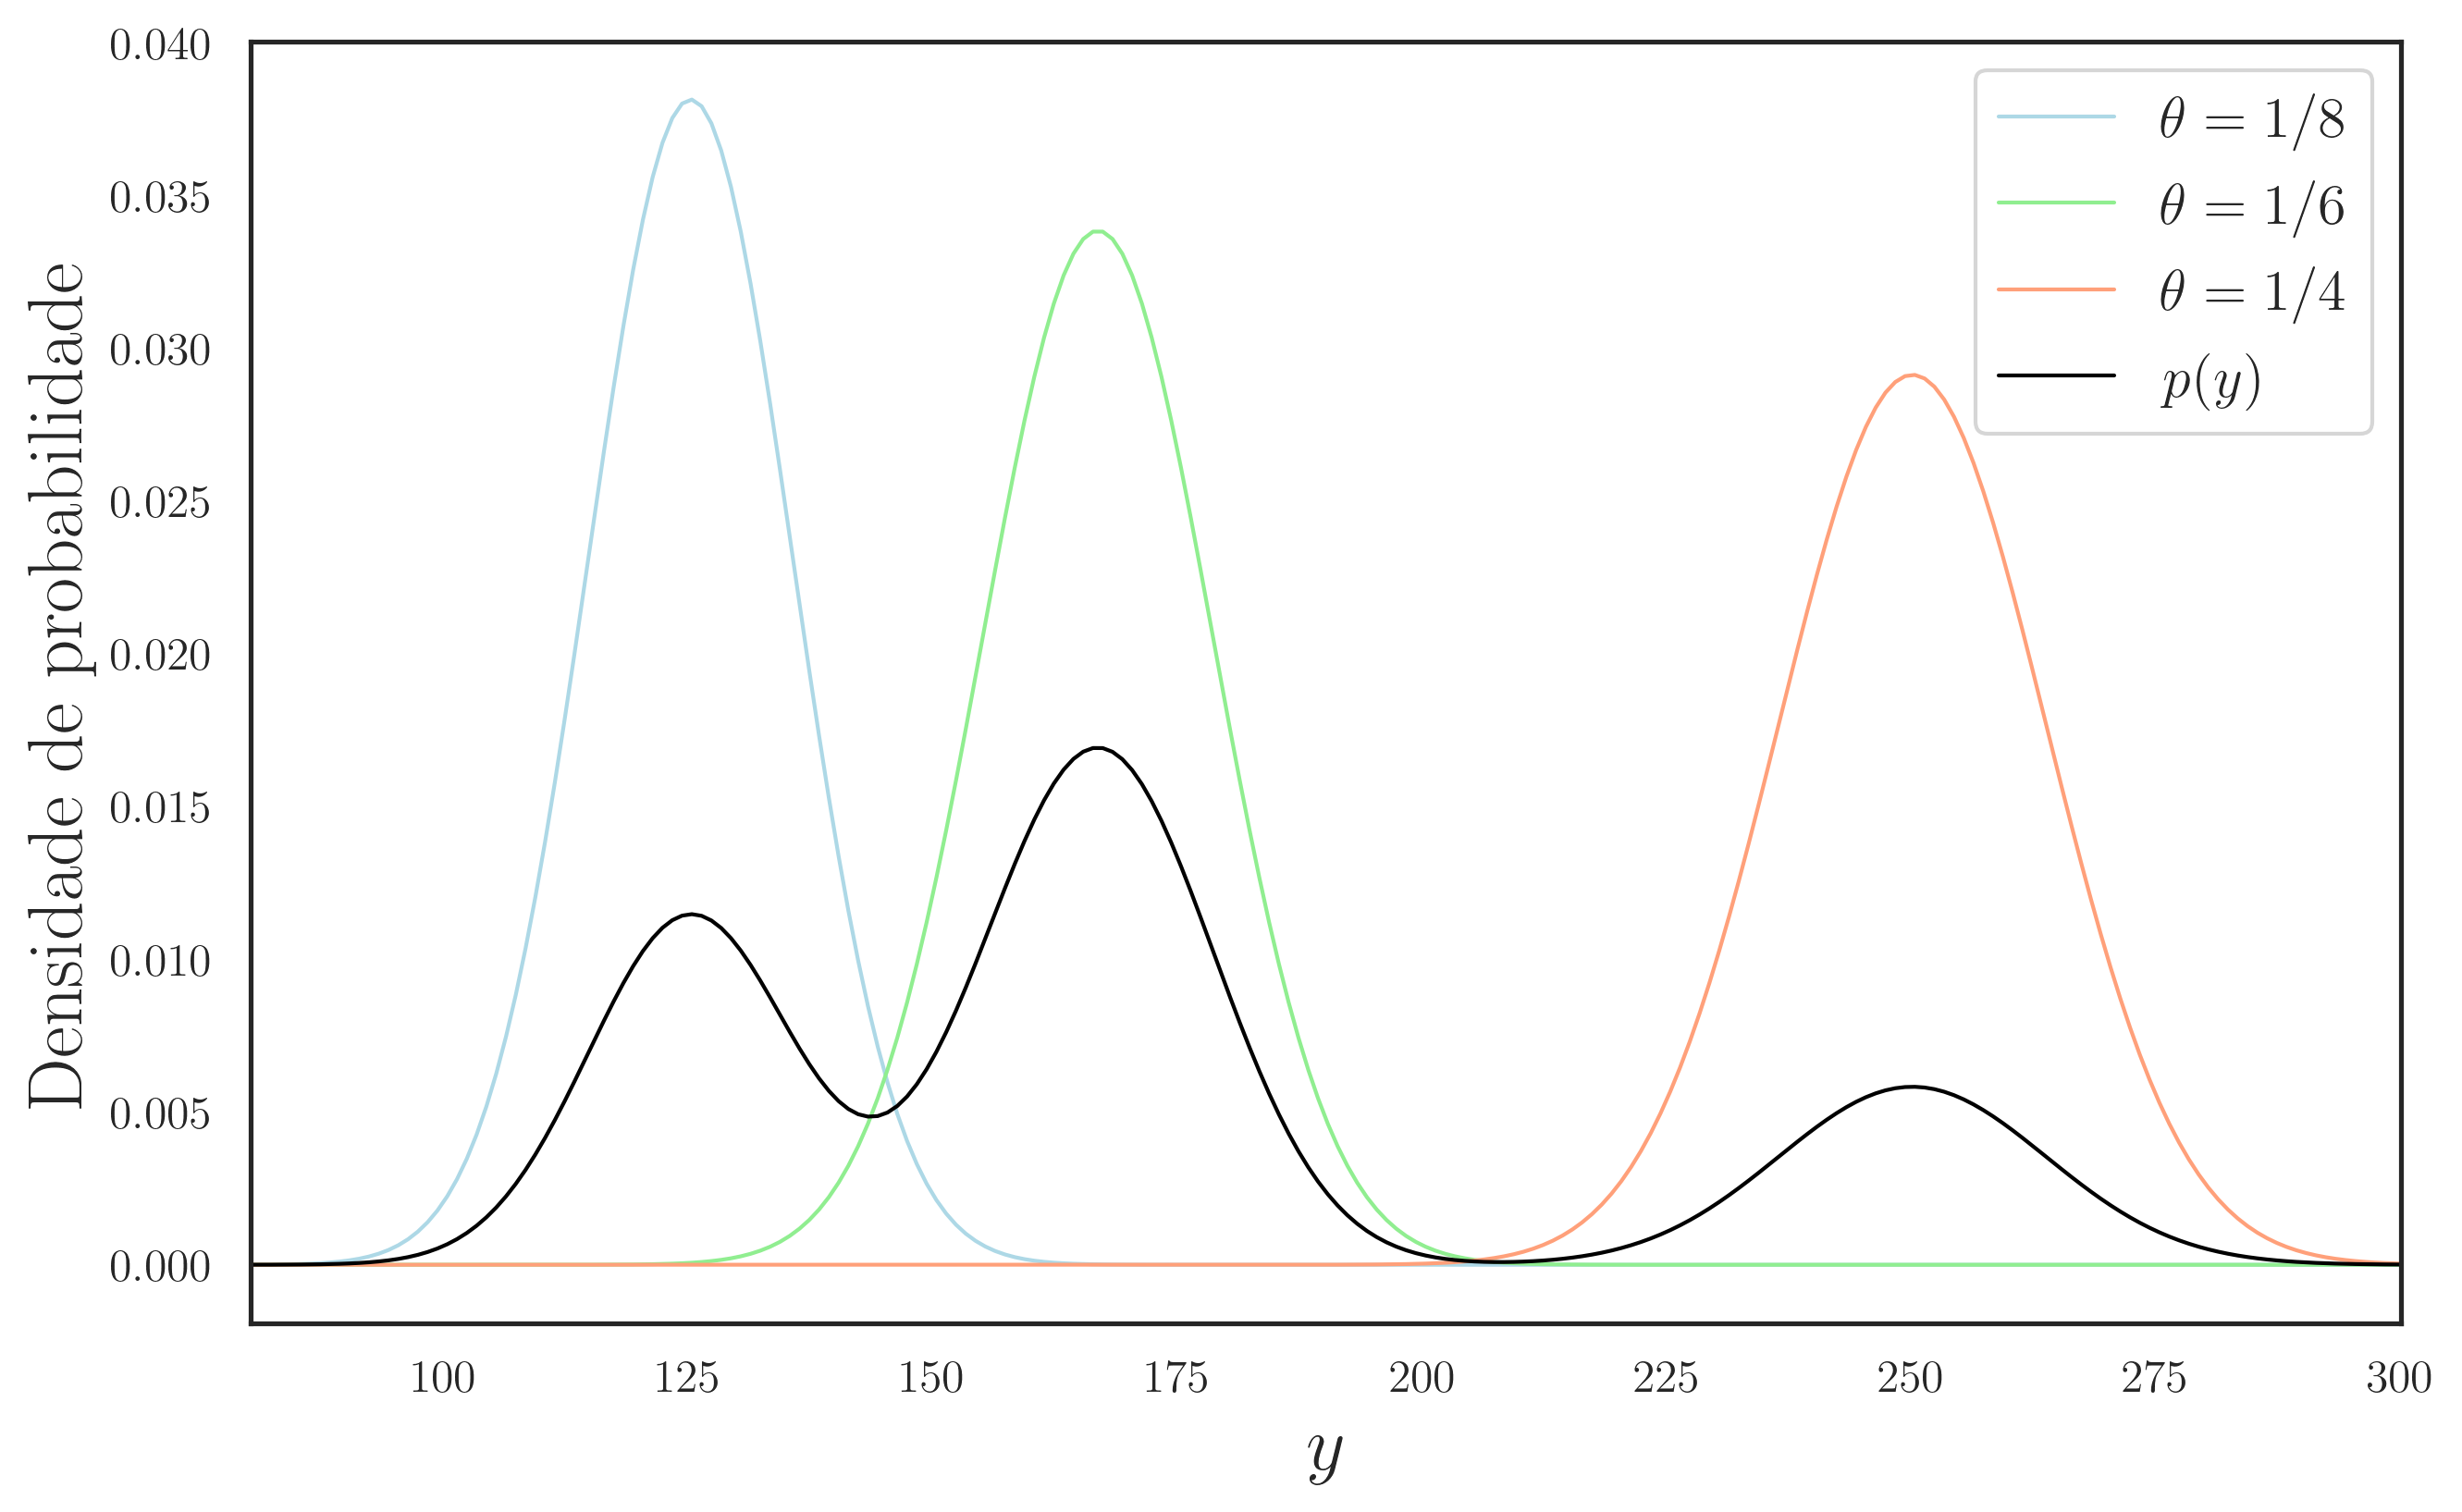

In [107]:
plt.figure(figsize=(10, 6), dpi=300)

gaussians = []

for sigma_i, mu_i, color, label in zip(sigma, mu, colors, labels):

    gaussian = normal_dist(x, sigma_i, mu_i)

    gaussians.append(gaussian)

    plt.plot(x, gaussian, color=color, label=label, lw=1.0)

p_y = (0.3 * gaussians[0] + 0.5 * gaussians[1] + 0.2 * gaussians[2])

plt.plot(x, p_y, color='black', linewidth=1.0, label=r'$p(y)$')

plt.xlabel(r'$y$')
plt.ylabel('Densidade de probabilidade')
plt.xlim(80, 300)
plt.legend()

plt.show()

In [108]:
y = np.linspace(0, 1000, 10000)

F1 = 0.5 + 0.5 * erf((y - mu[0]) / (np.sqrt(2) * sigma[0]))

F2 = 0.5 + 0.5 * erf((y - mu[1]) / (np.sqrt(2) * sigma[1]))

F3 = 0.5 + 0.5 * erf((y - mu[2]) / (np.sqrt(2) * sigma[2]))

F = (0.3 * F1 + 0.5 * F2 + 0.2 * F3)

y_quantiles = []

for a in quantiles:

    indice = np.argmin(np.abs(F - a))

    y_quantiles.append(y[indice])

    print(f'p(y < {y[indice]:.1f}) = {a:.2f}')

p(y < 114.9) = 0.05
p(y < 134.9) = 0.25
p(y < 163.7) = 0.50
p(y < 181.8) = 0.75
p(y < 259.2) = 0.95


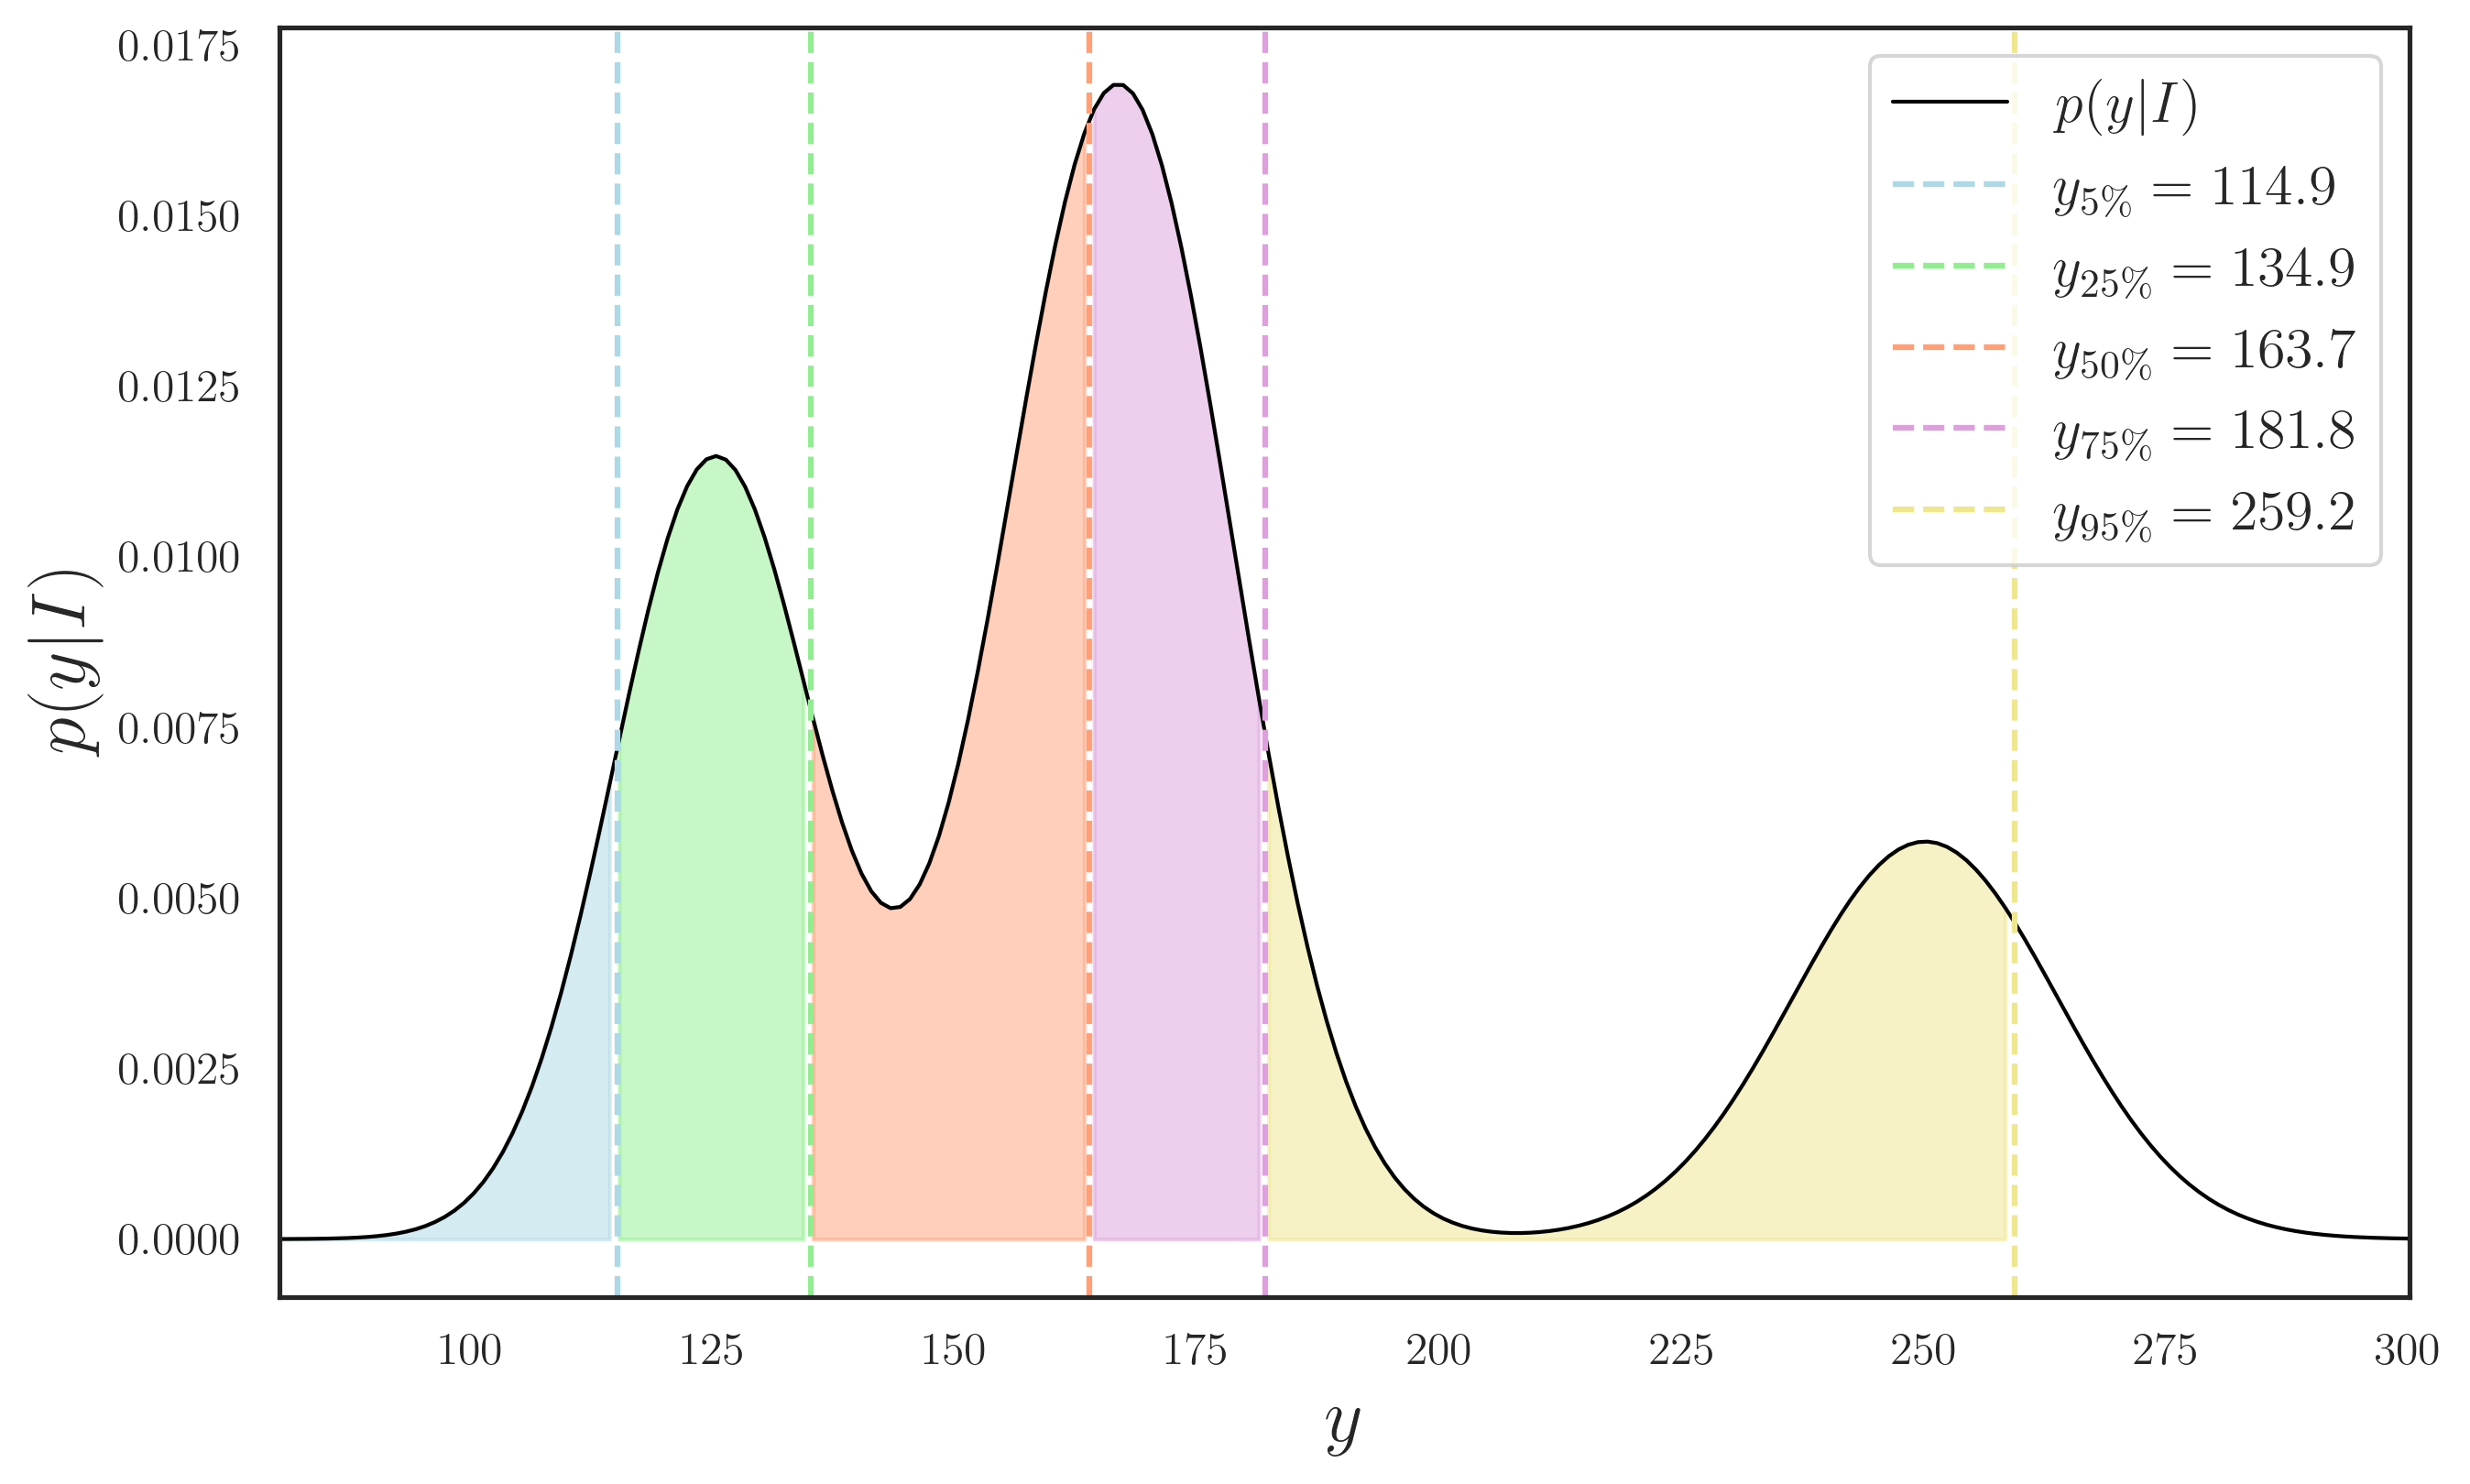

In [109]:
plt.figure(figsize=(10, 6), dpi=300)

plt.plot(x, p_y, color='black', linewidth=1.0, label=r'$p(y|I)$')

limites = [x[0], y_quantiles[0], y_quantiles[1], y_quantiles[2], y_quantiles[3], y_quantiles[4]]

for i in range(5):
    plt.fill_between(x, 0, p_y, where=(x >= limites[i]) & (x <= limites[i+1]), color=colors[i], alpha=0.5)

for a, y_q, color in zip(quantiles, y_quantiles, colors):
    plt.axvline(y_q, color=color, linestyle='--', linewidth=1.5, label=fr'$y_{{{100*a:.0f}\%}} = {y_q:.1f}$')

plt.xlabel(r'$y$')
plt.ylabel(r'$p(y|I)$')
plt.xlim(80, 300)
plt.legend(fontsize=15)

plt.show()

## Exercício 2 — Localização de um farol

### a) Visualização da taxa de variação

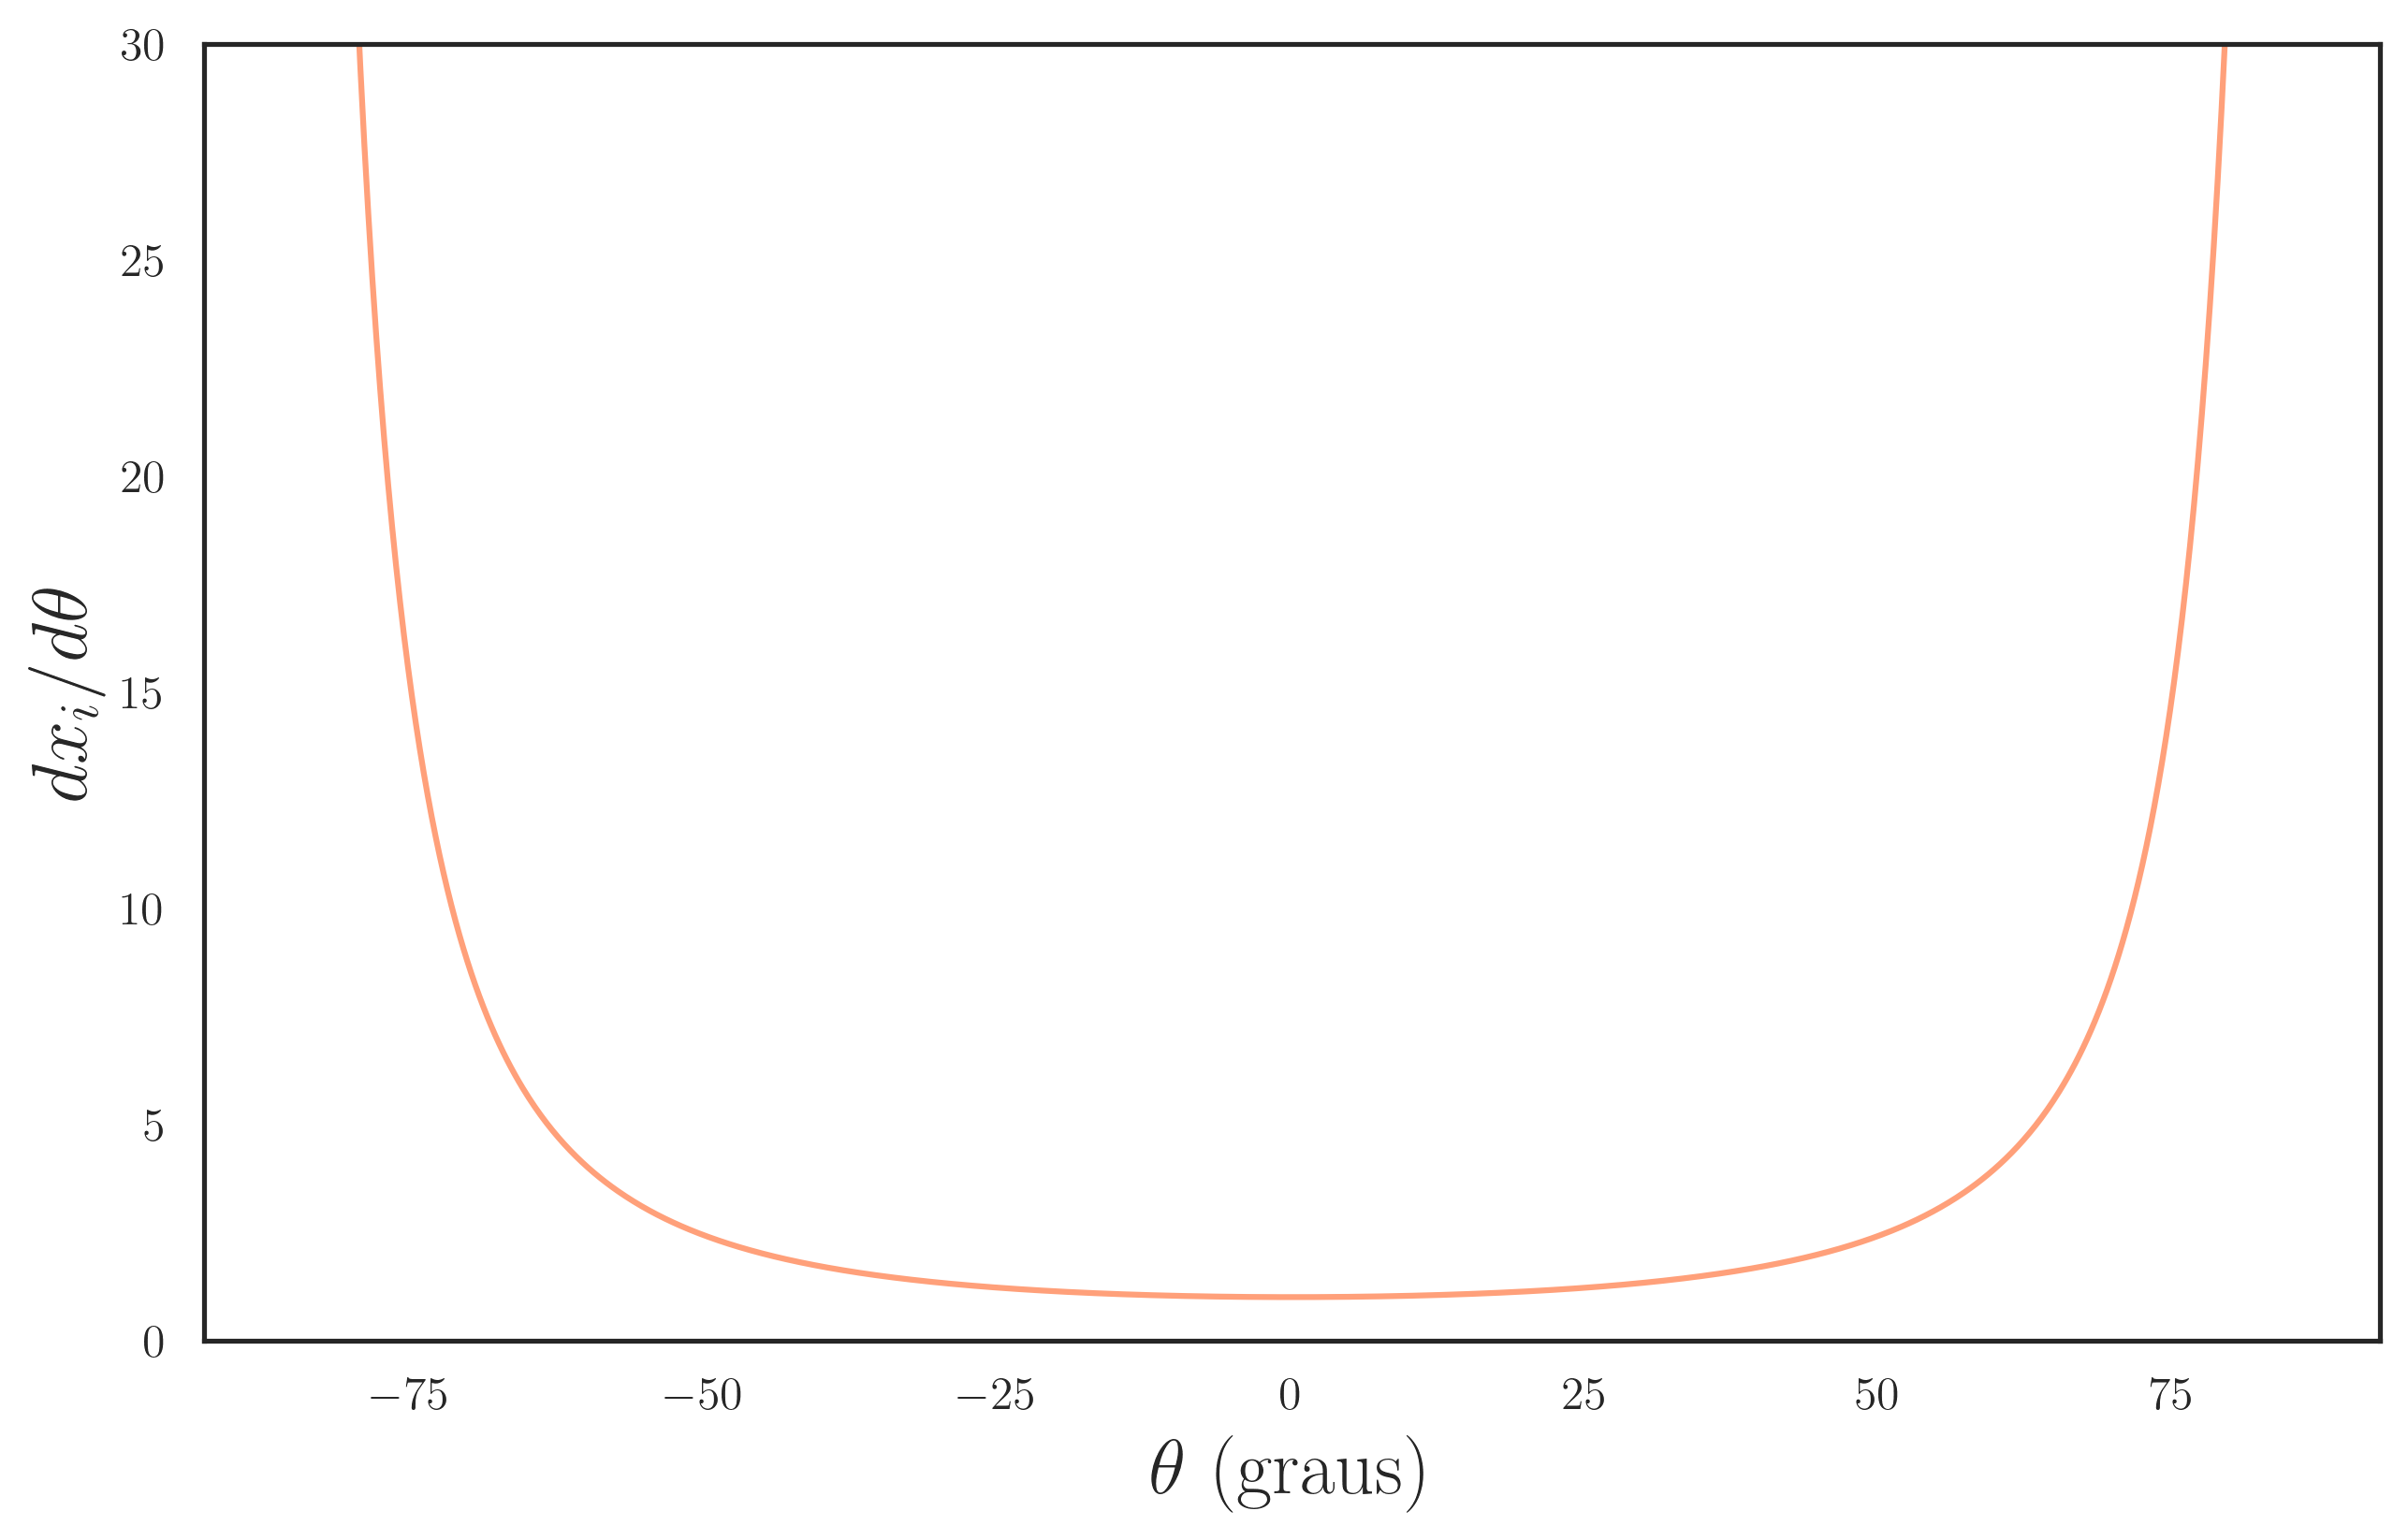

In [110]:
y_farol = 1.0 # valor dado pelo item b

theta = np.linspace(-np.pi/2 + 0.1, np.pi/2 - 0.1, 1000)

dx_dtheta = y_farol / np.cos(theta)**2

plt.figure(figsize=(10, 6), dpi=300)
plt.plot(np.degrees(theta), dx_dtheta, color=colors[2], lw=1.5)
plt.xlabel(r'$\theta$ (graus)')
plt.ylabel(r'$dx_i/d\theta$')
plt.ylim(0, 30)

plt.show()


### b) Posteriores e estimativas da posição $x_i$

In [111]:
data = [[-2.4, 3.7, 3.9, -52.6, 4.2, 1.3, 2.9], 
         [-3.2, 0.5, 4.5, 2.8, 2.3, 10.9, 2.7, 2.6, 9.9, 3.8, 3.7, 5.2, 5.0, 2.2, 6.3, 4.3, -73.5, 2.0, 0.6, 3.4, 1.3, 3.6, 1.2, -0.8, 3.3, 4.5, 1.6, 2.1, 5.2], 
         [1.8, 0.9, -0.6, 1.2, -1.0, 2.5, 3.4, 1.9, 1.8, 3.0, -1.7, 1.2, -1.2, 3.1, -0.1, 3.4, 3.1, 2.8, 2.9, 4.0, 5.0, 4.0, 2.4, 7.5, 12.7, 4.2, 4.1, 3.4, -14.3, 3.8, 1.9, 9.6, 2.5, 4.2, -28.4, 4.1, 22., 2.9, 2.3, 4.0, 5.0, 3.6, 2.4, -30.9, 2.4, 1.2, 8., 3.2, 1.3, 2.8, 5.0, 4.9, -2.9, 142.1, 2.6, 3.1, 3.1, 4.5, 3.6, 3.8, 2.3, 4.8, 3.0, 3.5]]

y_farol = 1.0

x_farol = np.linspace(-10, 10, 10000)

def likelihood_farol(xi, x_farol):
    return (1/np.pi) * y_farol / ((xi - x_farol)**2 + y_farol**2)

def posterior_farol(dados):
    likelihood = np.ones_like(x_farol)

    for xi in dados:
        likelihood *= likelihood_farol(xi, x_farol)

    norm = np.trapezoid(likelihood, x_farol)

    posterior = likelihood / norm

    x_map = x_farol[np.argmax(posterior)]

    return posterior, x_map


Conjunto 1: x_farol = 3.5034 km
Conjunto 2: x_farol = 2.9713 km
Conjunto 3: x_farol = 3.0693 km


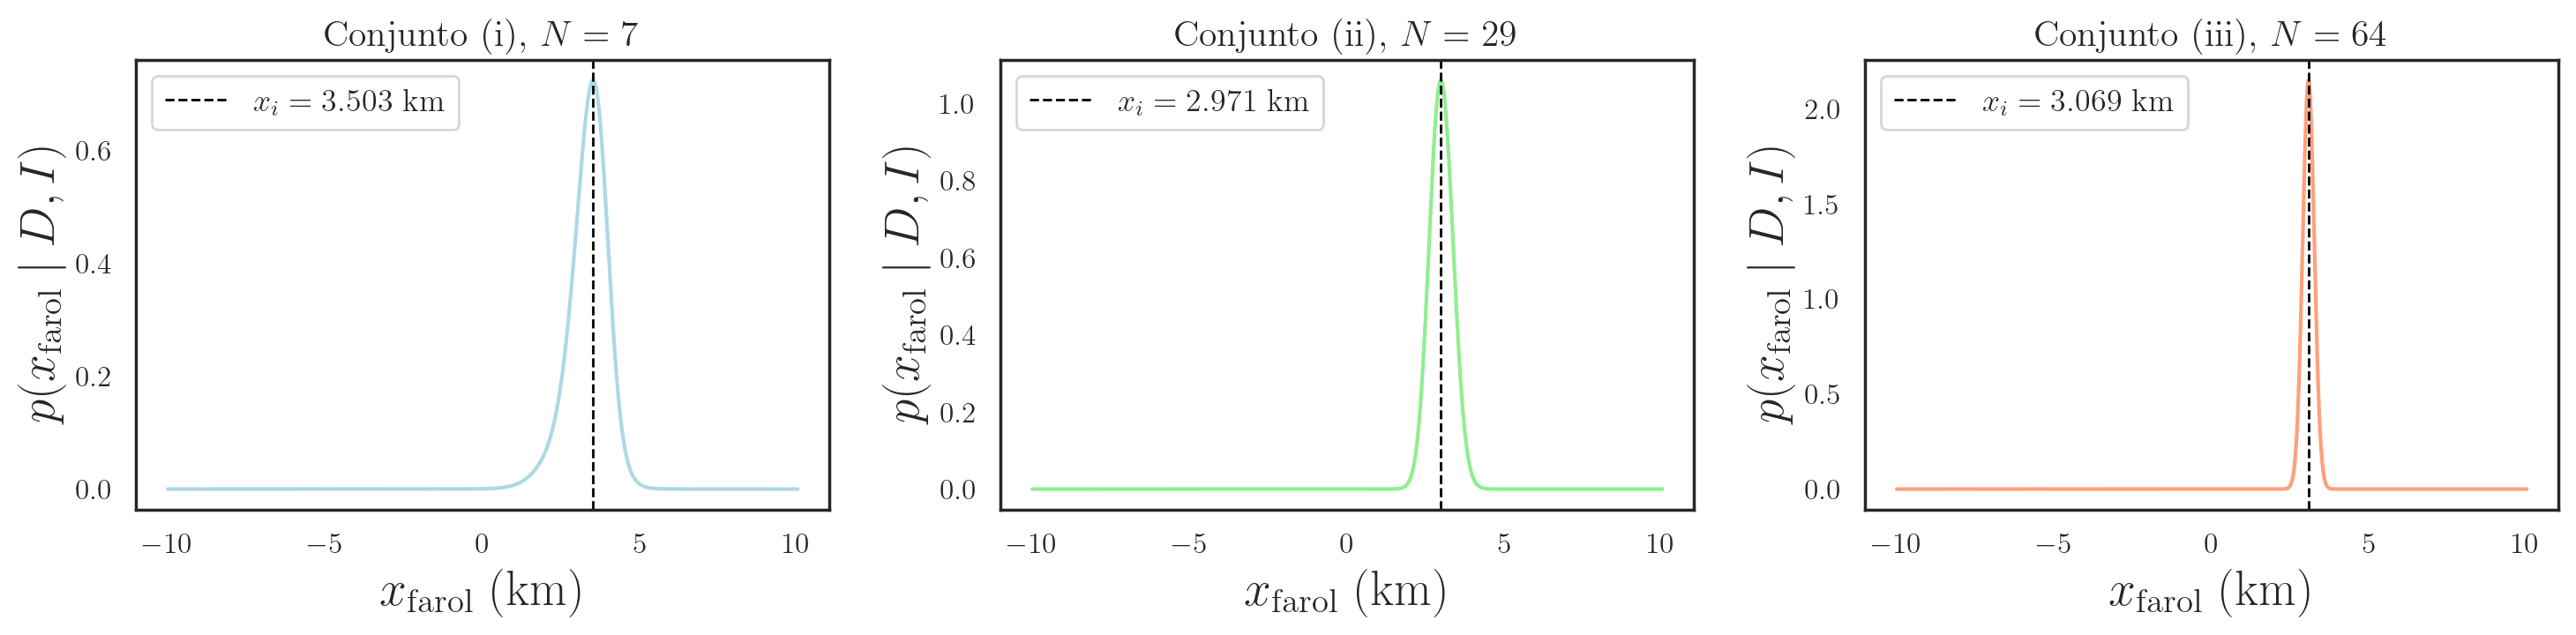

In [112]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4), dpi=200)

for i, set in enumerate(data):

    posterior, x_i = posterior_farol(set)

    ax[i].plot(x_farol, posterior, color=colors[i], lw=1.5)

    ax[i].axvline(x_i, color='black', ls='--', lw=1.0, label=fr'$x_i= {x_i:.3f}$ km')

    ax[i].set_title(fr'Conjunto {["(i)", "(ii)", "(iii)"][i]}, $N={len(set)}$')

    ax[i].set_xlabel(r'$x_{\mathrm{farol}}$ (km)')
    ax[i].set_ylabel(r'$p(x_{\mathrm{farol}}\mid D,I)$')

    ax[i].legend(fontsize=13)

    print(f'Conjunto {i+1}: 'f'x_farol = {x_i:.4f} km')

plt.tight_layout()
plt.show()


## Exercício 4 - Distribuição da média de variáveis Beta

### a) PDFs para $n = 1, 3, 5, 8$

In [113]:
def beta_pdf(x):
    return np.where((x >= 0) & (x <= 1), 20 * x * (1 - x)**3, 0)

x = np.linspace(0, 1, 1000)
dx = x[1] - x[0]

f_x = beta_pdf(x)
f_x = f_x / np.trapezoid(f_x, x) 

n_values = [1, 3, 5, 8]

pdfs = {}
mus = {}
sigmas = {}

In [114]:
f_y = f_x.copy()

for n in range(1, 9):

    if n > 1:
        f_y = np.convolve(f_y, f_x, mode='full') * dx

    if n in n_values:

        y = np.arange(len(f_y)) * dx

        x_media = y / n
        f_media = n * f_y

        area = np.trapezoid(f_media, x_media)
        f_media = f_media / area

        pdfs[n] = (x_media, f_media)

        mu = np.trapezoid(x_media * f_media, x_media)

        var = np.trapezoid((x_media - mu)**2 * f_media, x_media)

        mus[n] = mu
        sigmas[n] = var

        print(f'n = {n}: '
            f'Área = {np.trapezoid(f_media, x_media):.3f}, '
            f'Média = {mu:.3f}, '
            f'Variância = {var:.3f}')

n = 1: Área = 1.000, Média = 0.333, Variância = 0.032
n = 3: Área = 1.000, Média = 0.333, Variância = 0.011
n = 5: Área = 1.000, Média = 0.333, Variância = 0.006
n = 8: Área = 1.000, Média = 0.333, Variância = 0.004


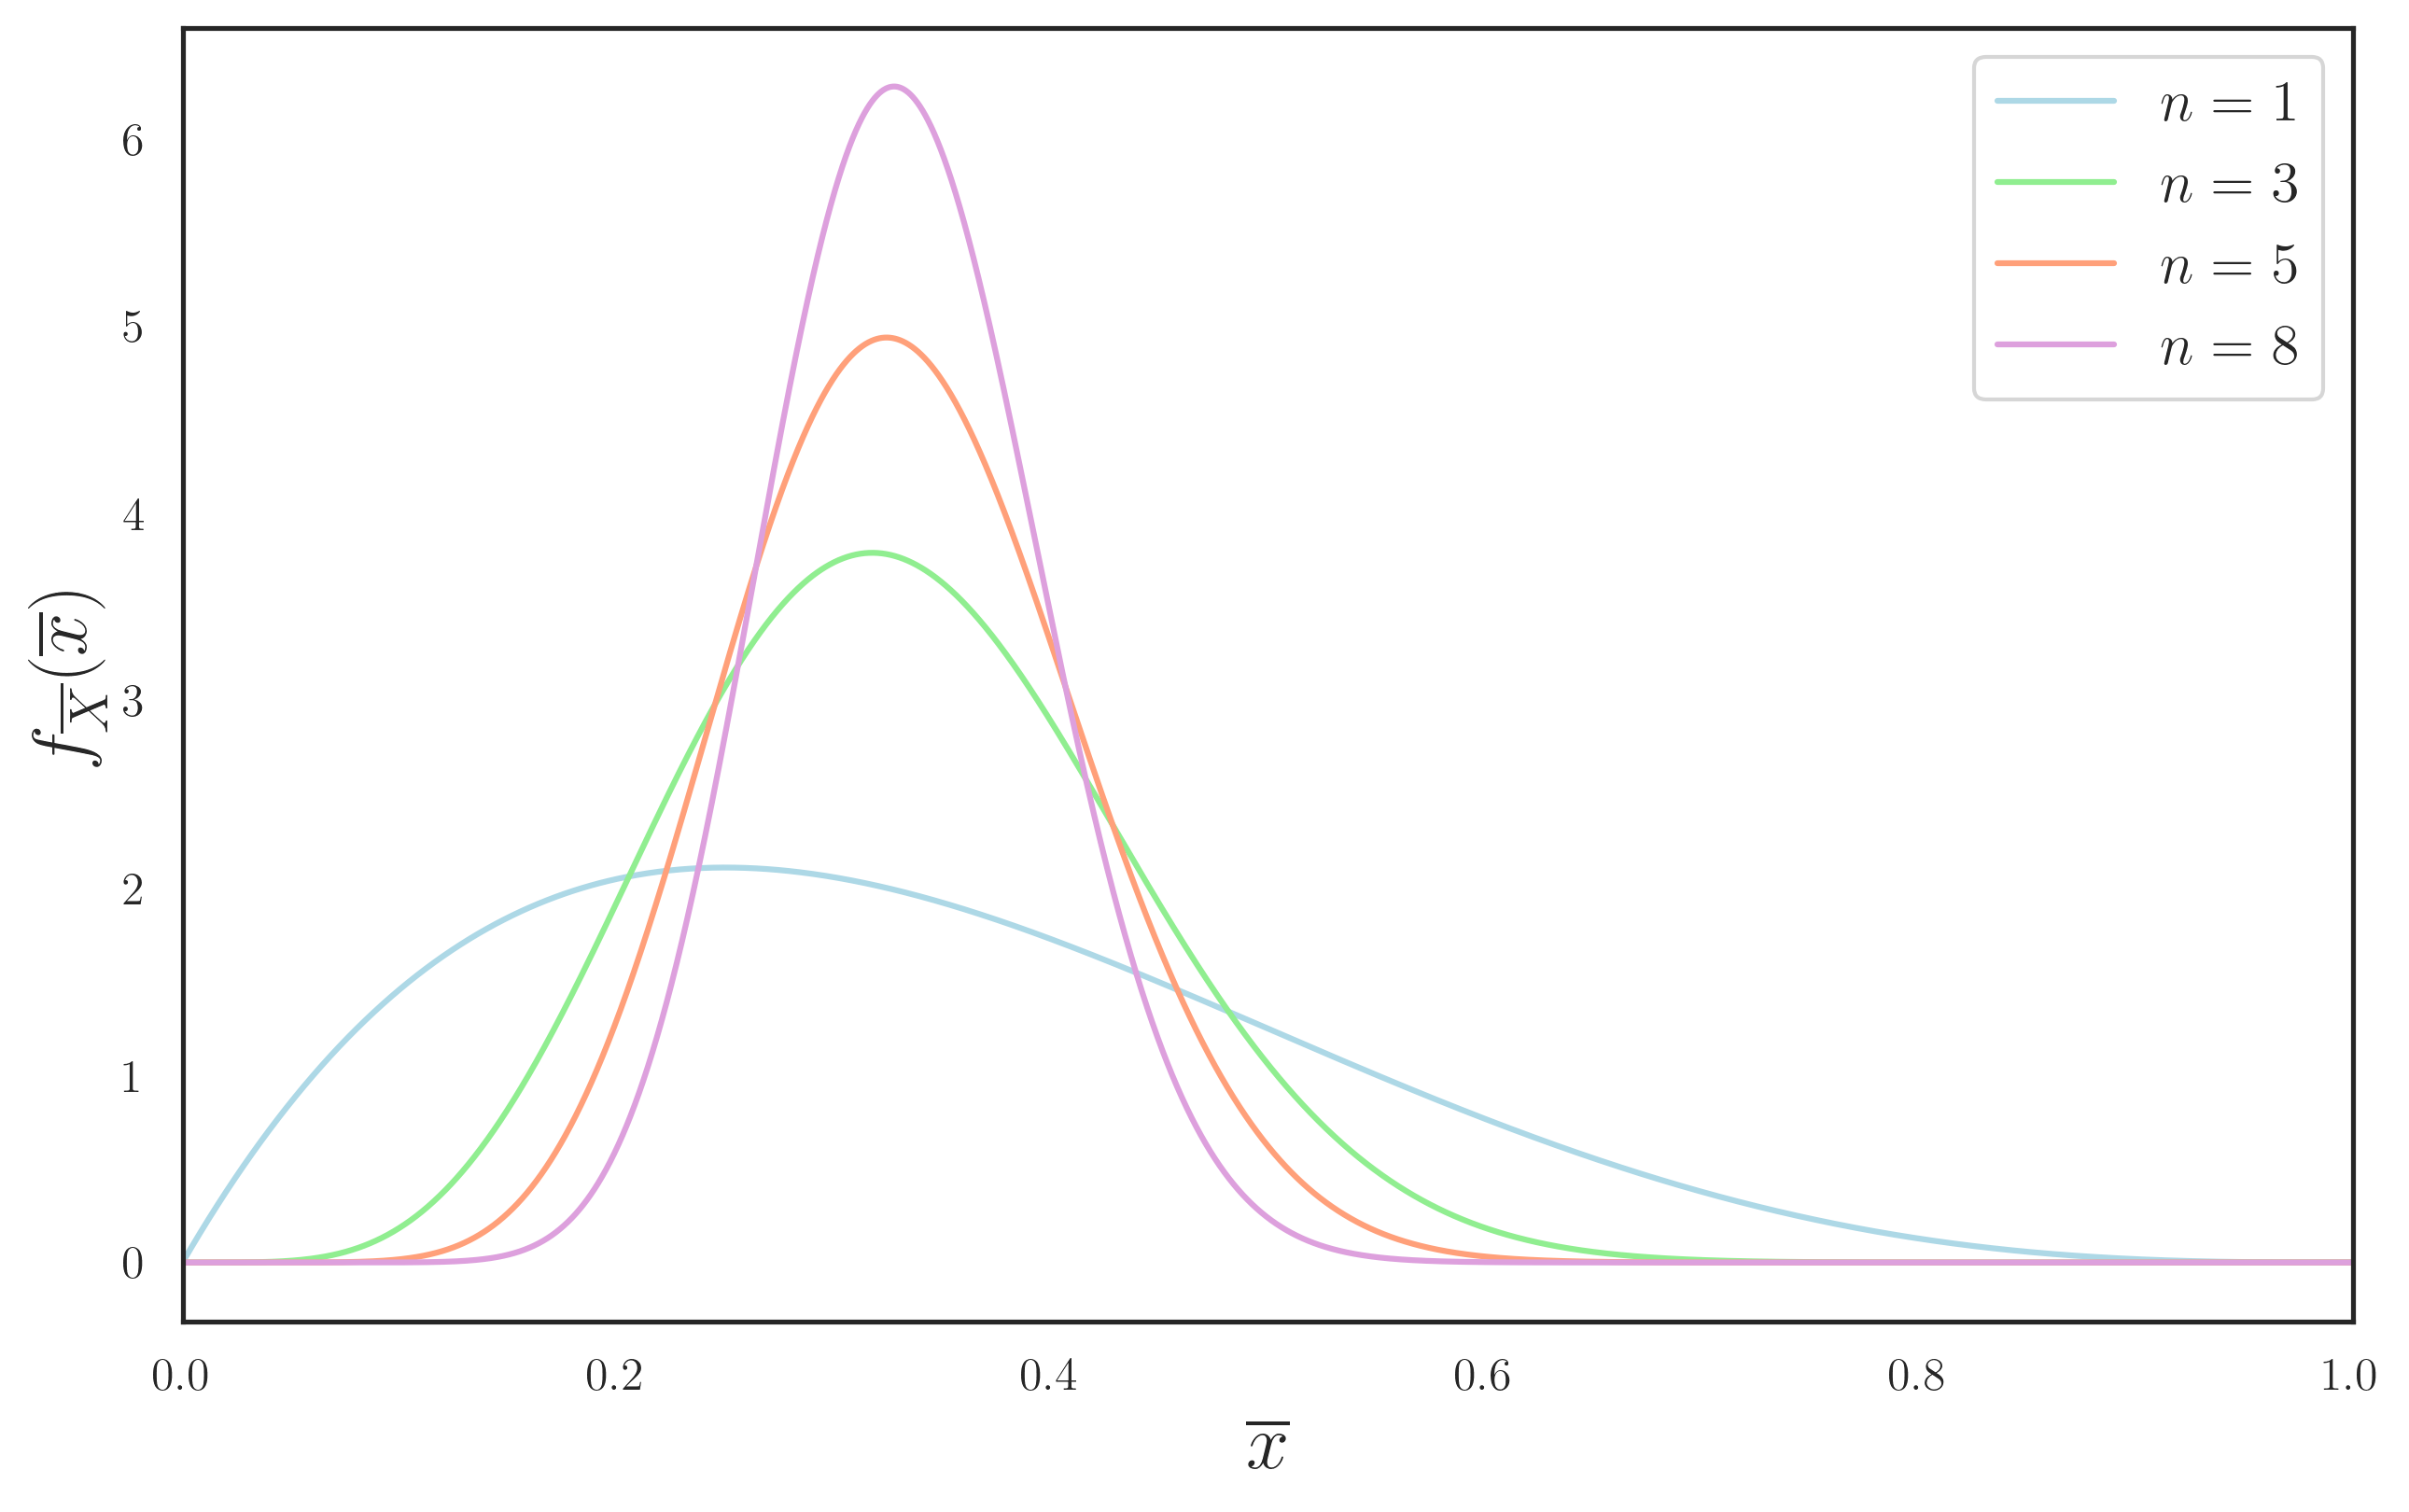

In [115]:
plt.figure(figsize=(10, 6), dpi=300)

for n, color in zip(n_values, colors):
    x_media, f_media = pdfs[n]

    plt.plot(x_media, f_media, color=color, lw=1.5, label=fr'$n={n}$')

plt.xlabel(r'$\overline{x}$')
plt.ylabel(r'$f_{\overline{X}}(\overline{x})$')
plt.xlim(0, 1)
plt.legend()
plt.show()


### c. Comparação com a aproximação Gaussiana

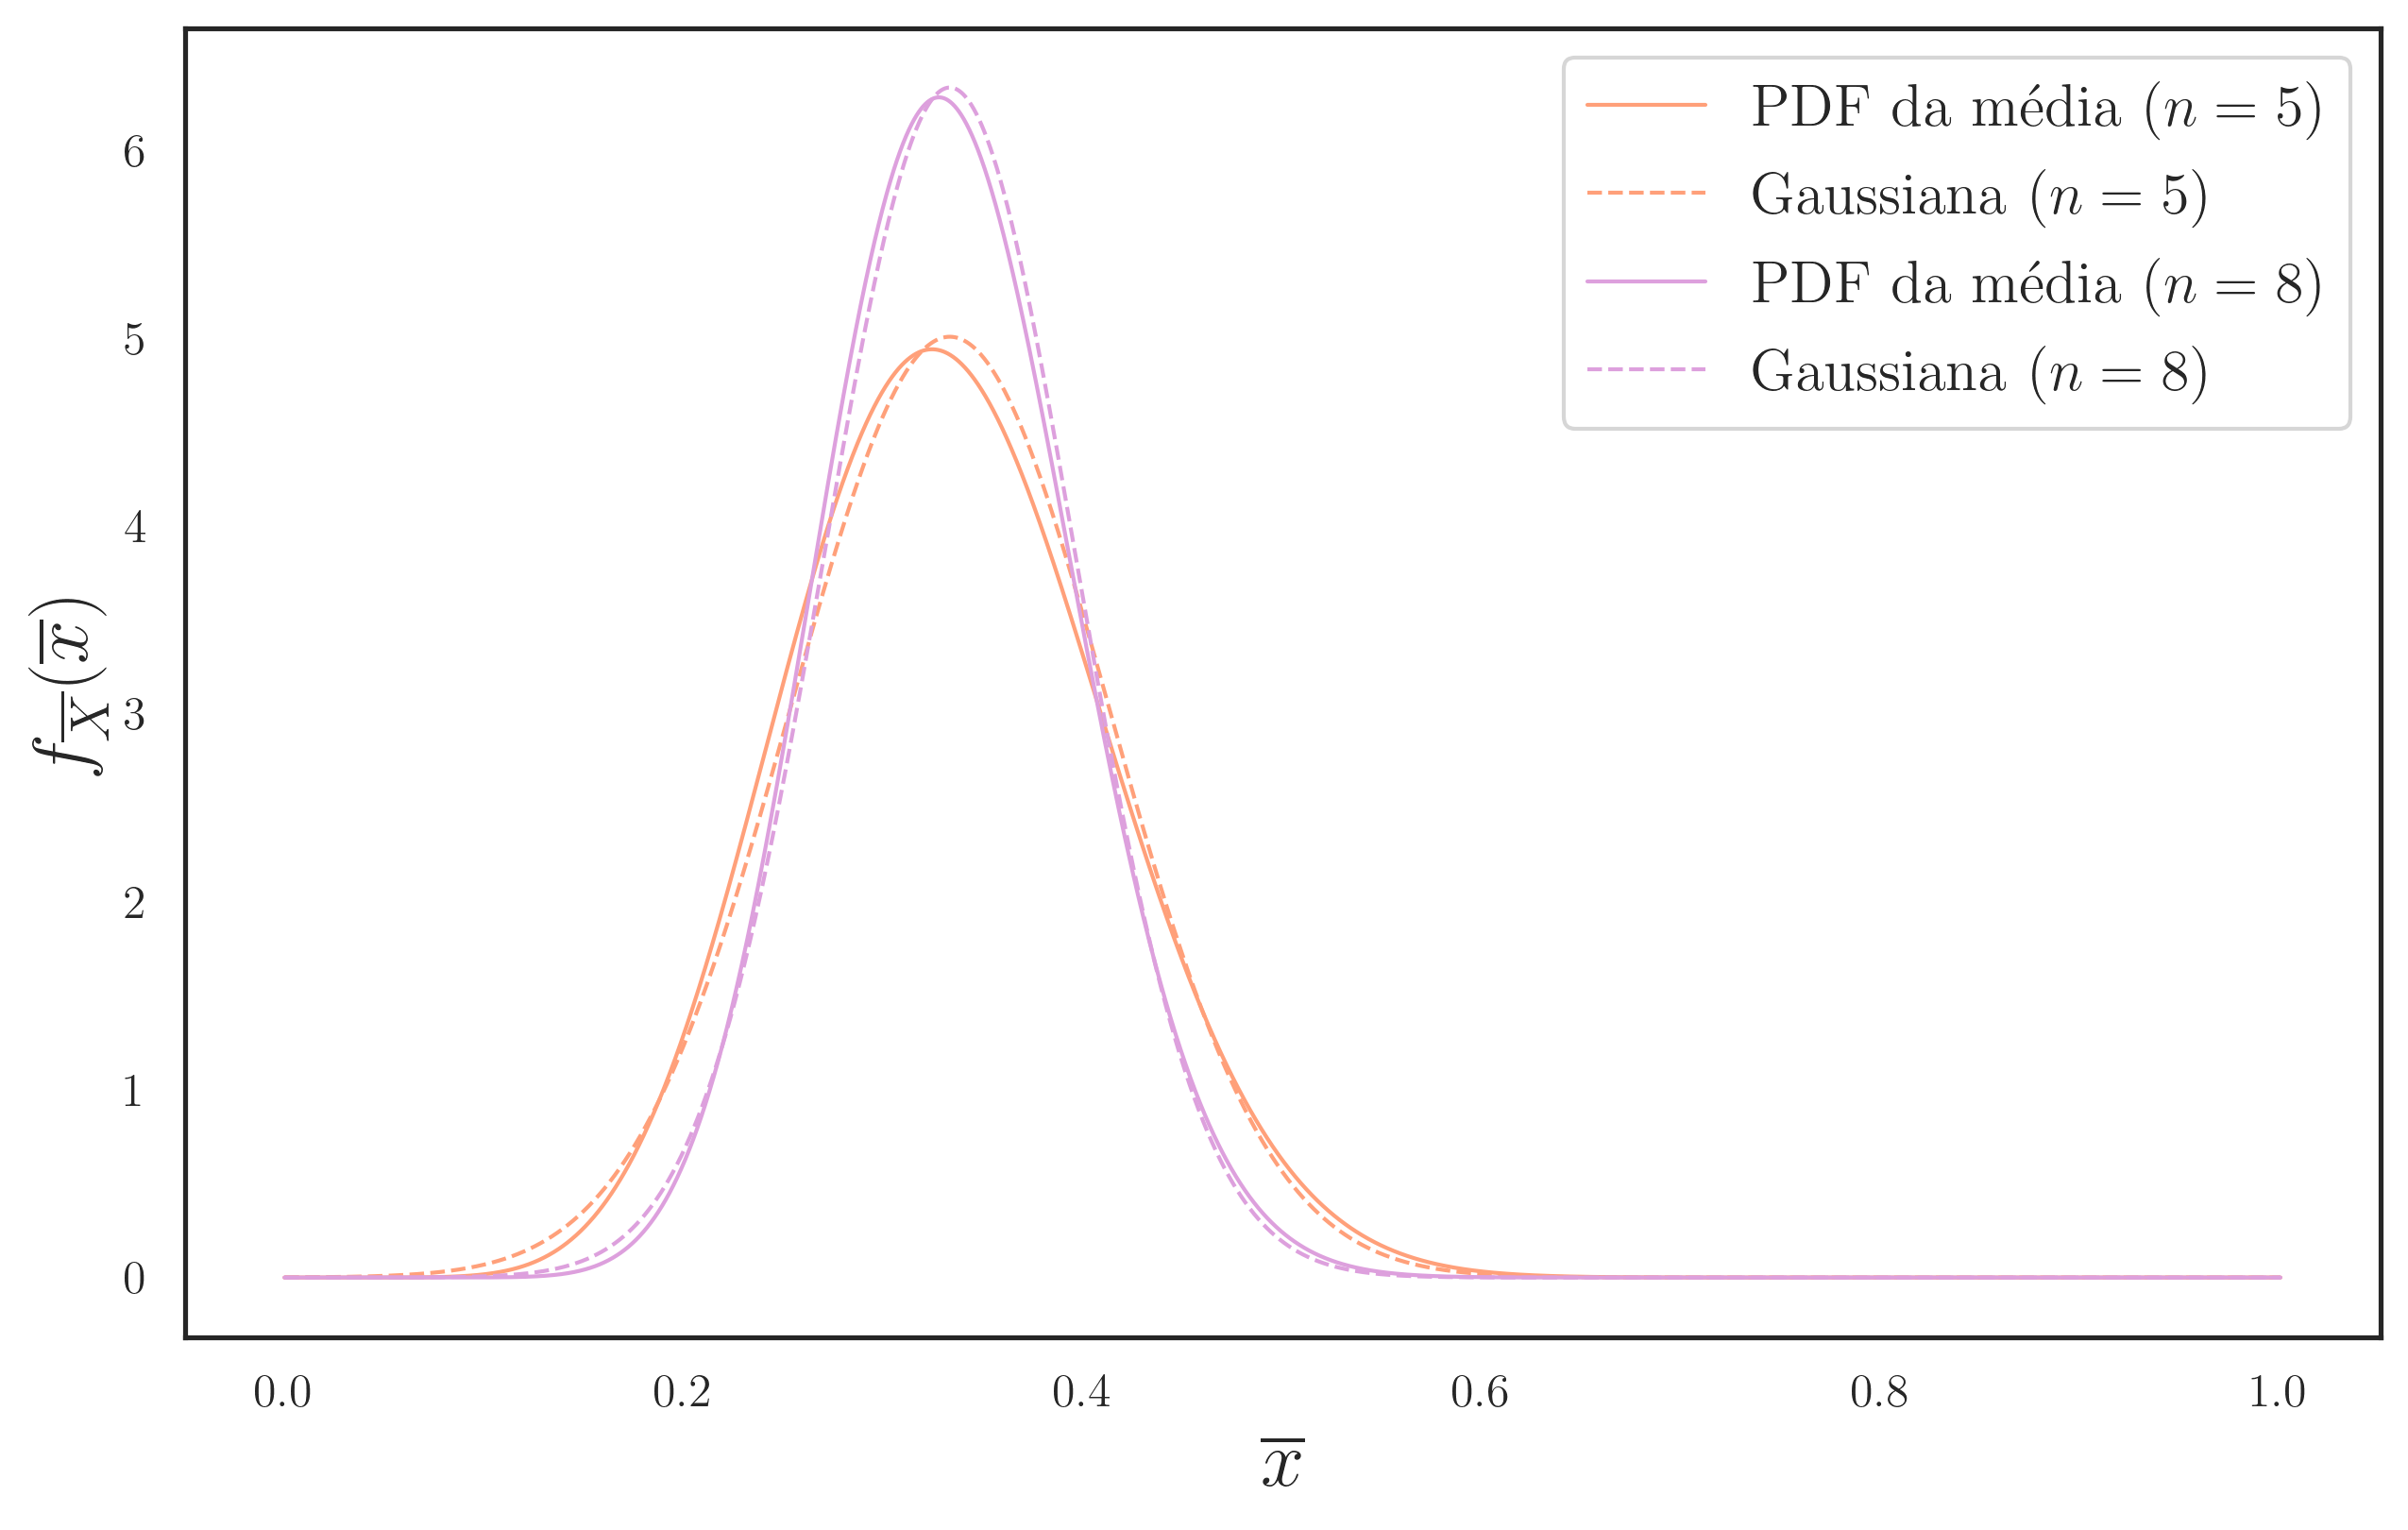

In [116]:
plt.figure(figsize=(10, 6), dpi=300)

for n, color in zip([5, 8], colors[2:4]):

    x_media, f_media = pdfs[n]

    mu = mus[n]
    sigma = np.sqrt(sigmas[n])

    gaussian = (1 / (np.sqrt(2 * np.pi) * sigma) * np.exp(-0.5 * ((x_media - mu) / sigma)**2))

    plt.plot(x_media, f_media, color=color, lw=1.0, label=fr'PDF da média ($n={n}$)')

    plt.plot(x_media, gaussian, color=color, ls='--', lw=1.0, label=fr'Gaussiana ($n={n}$)')

plt.xlabel(r'$\overline{x}$')
plt.ylabel(r'$f_{\overline{X}}(\overline{x})$')
plt.legend()
plt.show()

In [117]:
for n in [5, 8]:
    x_mean, f_mean = pdfs[n]

    mode = x_mean[np.argmax(f_mean)]

    print(f'n = {n}')
    print(f'Média = {mus[n]:.6f}')
    print(f'Moda  = {mode:.6f}')

n = 5
Média = 0.333334
Moda  = 0.324324
n = 8
Média = 0.333334
Moda  = 0.327953


## Exercício 5c: probabilidade de obter um valor $f \geq 3.33$ ao acaso, caso $\sigma_1^2 = 2\sigma_2^2$

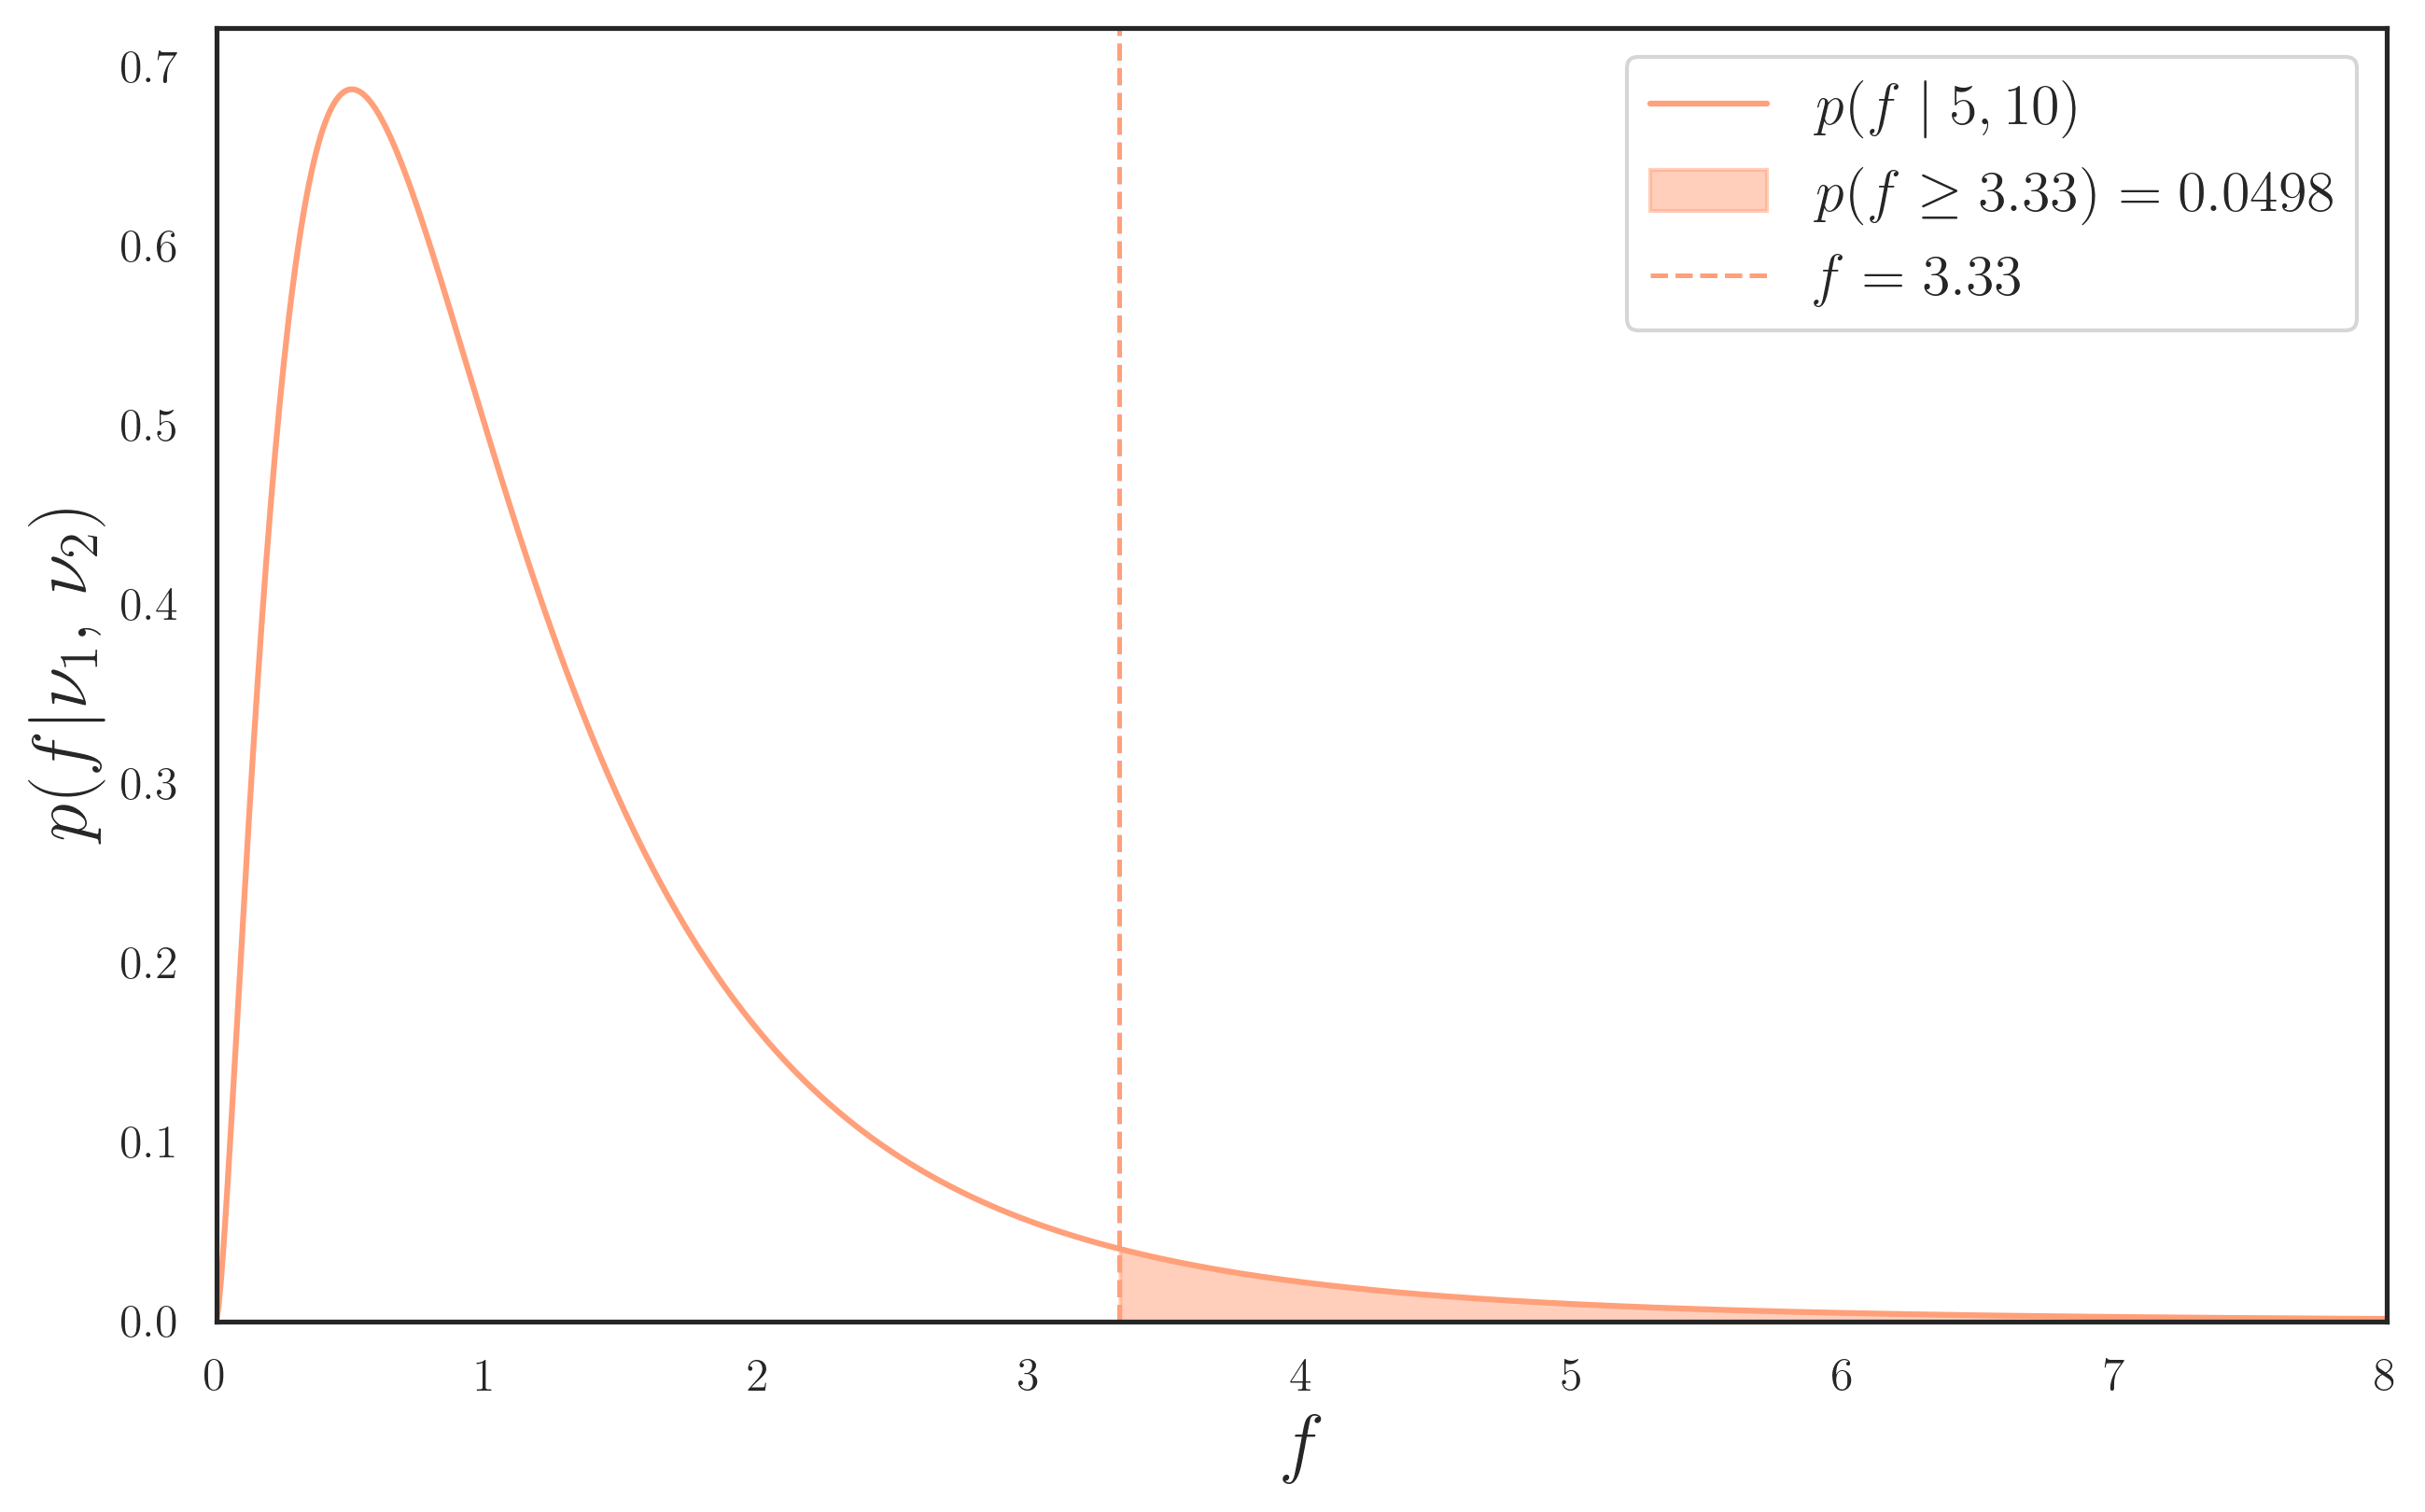

In [118]:
def f_pdf(x, nu1, nu2):
    a = (gamma((nu1 + nu2)/2) / (gamma(nu1/2) * gamma(nu2/2))) * (nu1/nu2)**(nu1/2)    
    return a * x**(nu1/2 - 1) / (1 + x*nu1/nu2)**((nu1 + nu2)/2)

nu1 = 5
nu2 = 10
f0 = 3.33

x = np.linspace(0.001, 8, 1000)
y = f_pdf(x, nu1, nu2)

integral, error = quad(lambda t: f_pdf(t, nu1, nu2), f0, np.inf)

plt.figure(figsize=(10, 6), dpi=300)

plt.plot(x, y, lw=1.5, label=rf'$p(f\mid {nu1},{nu2})$', color=colors[2])

mask = x >= f0
plt.fill_between(x[mask], y[mask], alpha=0.5, color=colors[2], label=rf'$p(f \geq {f0}) = {integral:.4f}$')

plt.axvline(f0, ls='--', lw=1.2, label=rf'$f={f0}$', color=colors[2])

plt.xlabel(r'$f$')
plt.ylabel(r'$p(f|\nu_1,\, \nu_2)$')
plt.xlim(0, 8)
plt.ylim(bottom=0)
plt.legend()
plt.grid(False)

plt.show()

## Exercício 6 - Prevalência

### (a) Likelihood, evidência e posterior exata

In [119]:
FPR = 0.01
FNR = 0.15
c = 1 - FNR - FPR
pmin = FPR / c

n = 250
r = 7

def likelihood(pa):
    p_positive = 0.84*pa + 0.01
    return comb(n, r) * p_positive**r * (1 - p_positive)**(n-r)

evidence, error = quad(likelihood, 0, 1)

def posterior(pa):
    return likelihood(pa) / evidence

norm, error = quad(posterior, 0, 1)

print(norm)

0.9999999999999999


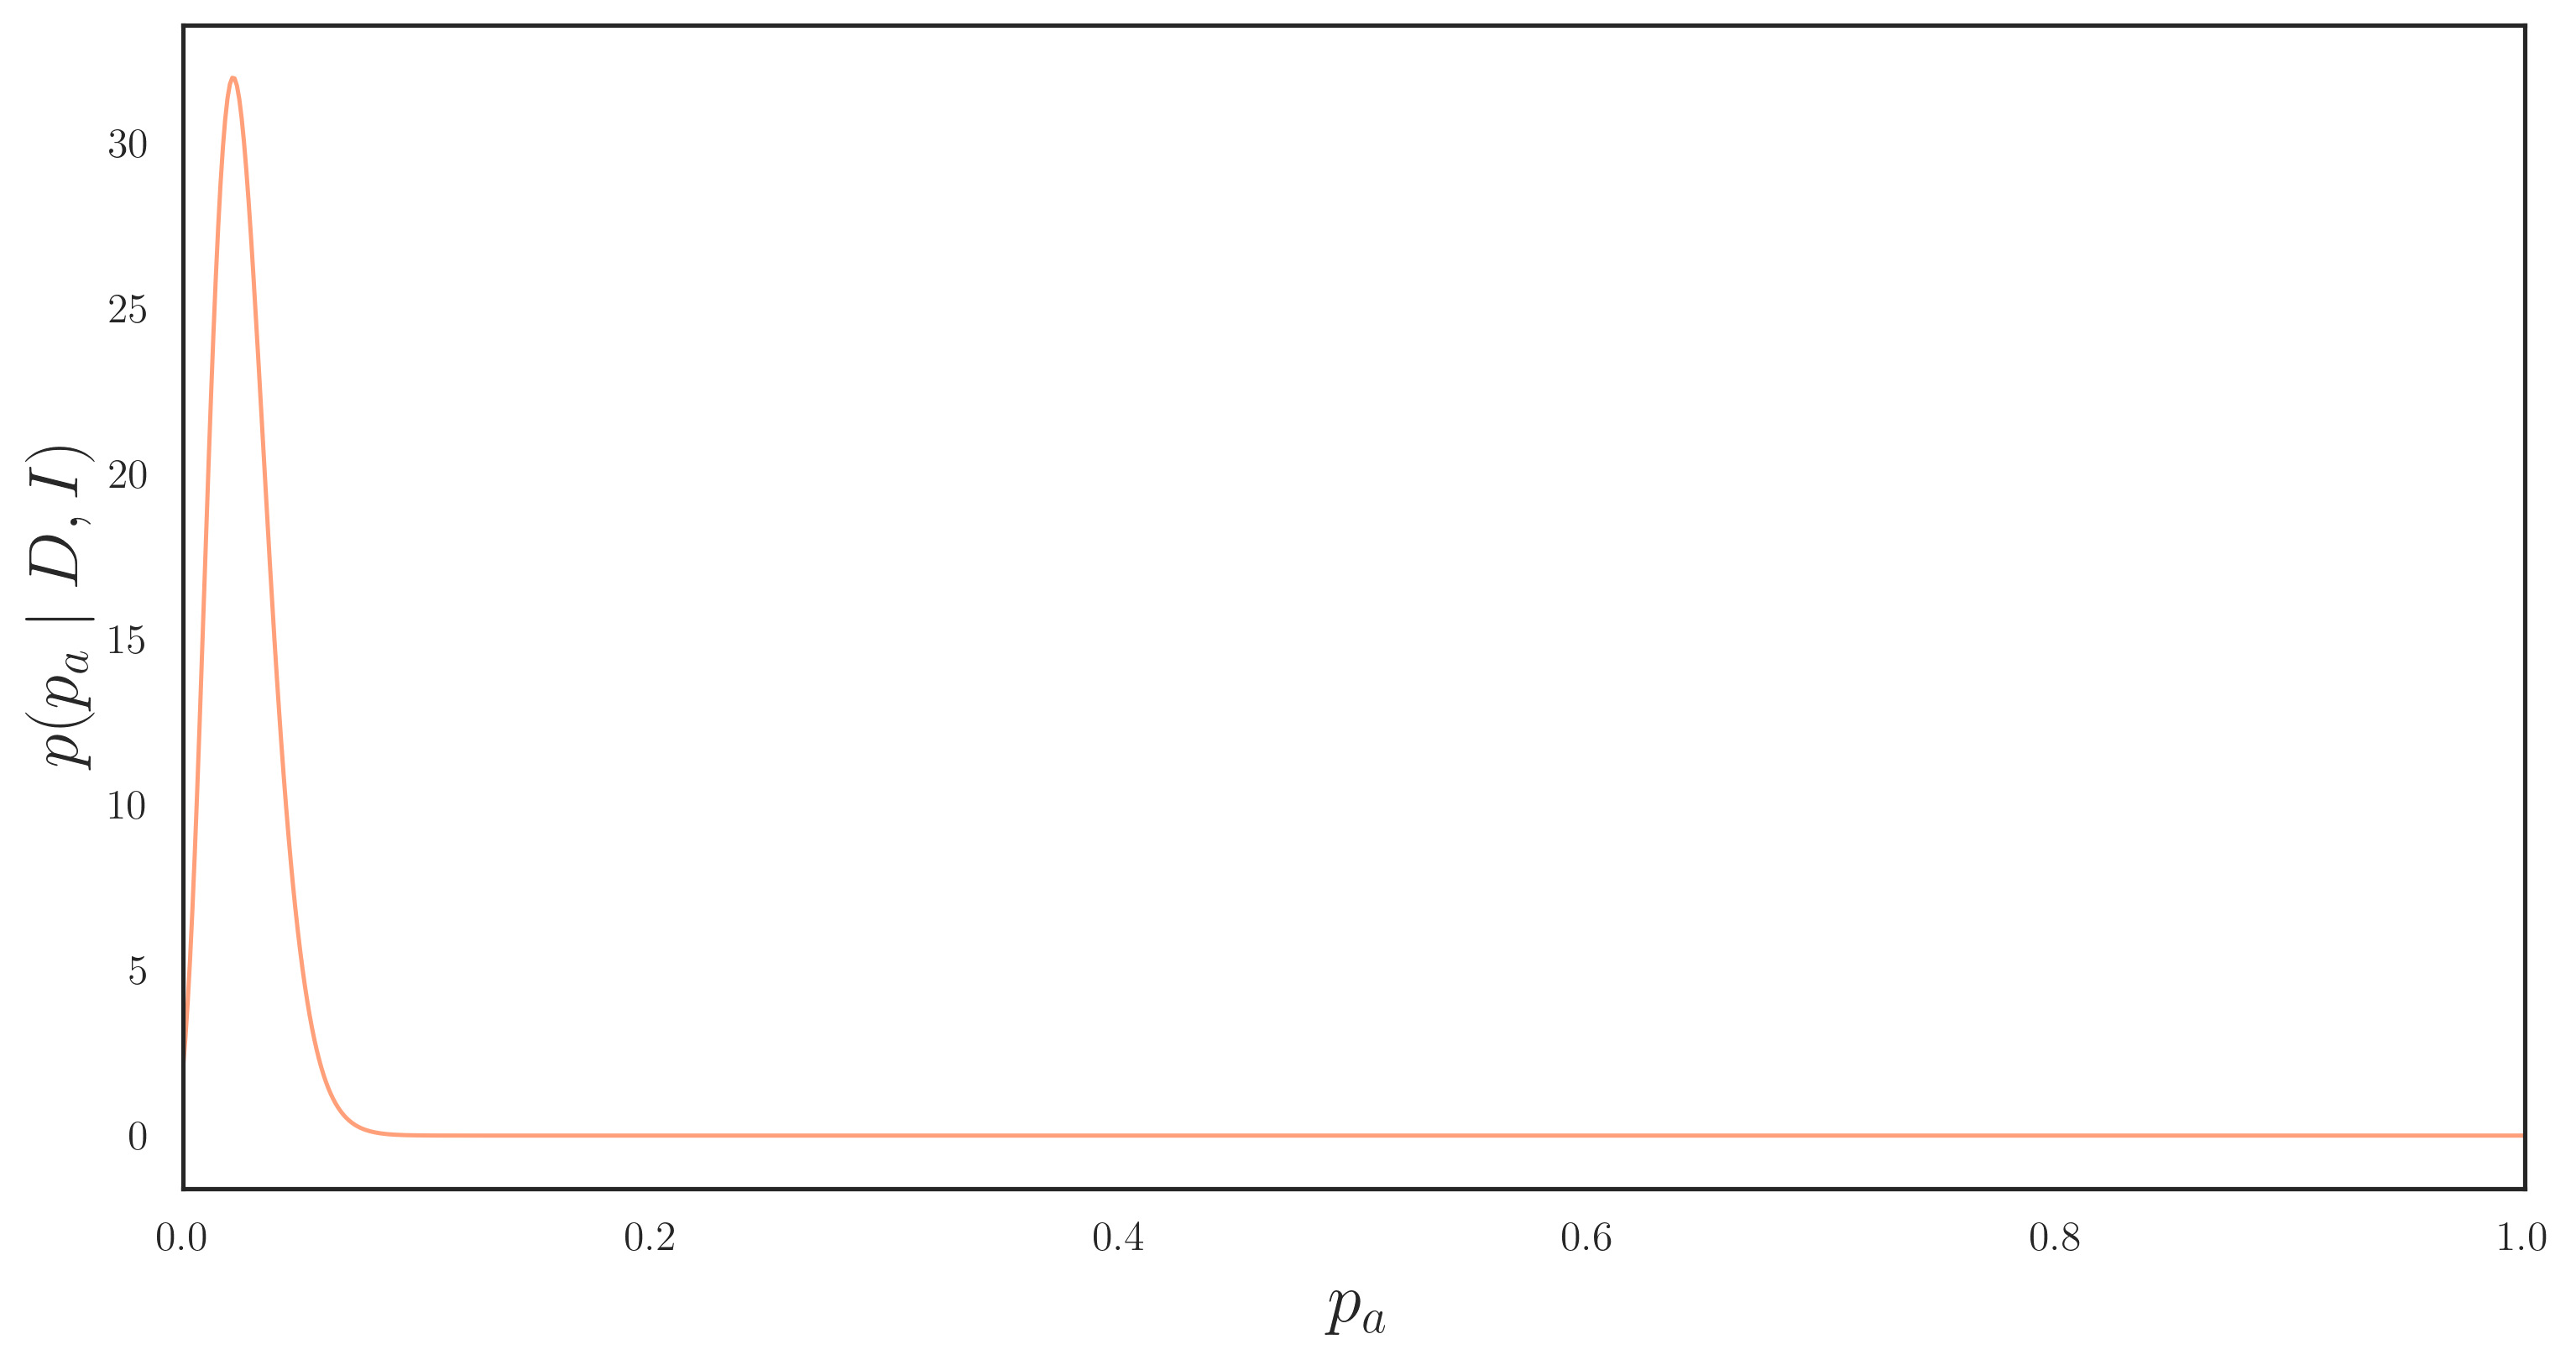

In [120]:
pa = np.linspace(0, 1, 1000)

plt.figure(figsize=(12, 6), dpi=300)

plt.plot(pa, posterior(pa), color=colors[2], lw=1.2)

plt.xlabel(r'$p_a$')
plt.ylabel(r'$p(p_a\mid D,I)$')
plt.xlim(0, 1)
plt.show()

In [121]:
result_6a = minimize_scalar(lambda pa: -posterior(pa), bounds=(0, 1), method='bounded')

pa_max = result_6a.x

print(f"Máximo da posterior: {pa_max:.4f}")

Máximo da posterior: 0.0214


### (b) Aproximação por distribuição Beta deslocada

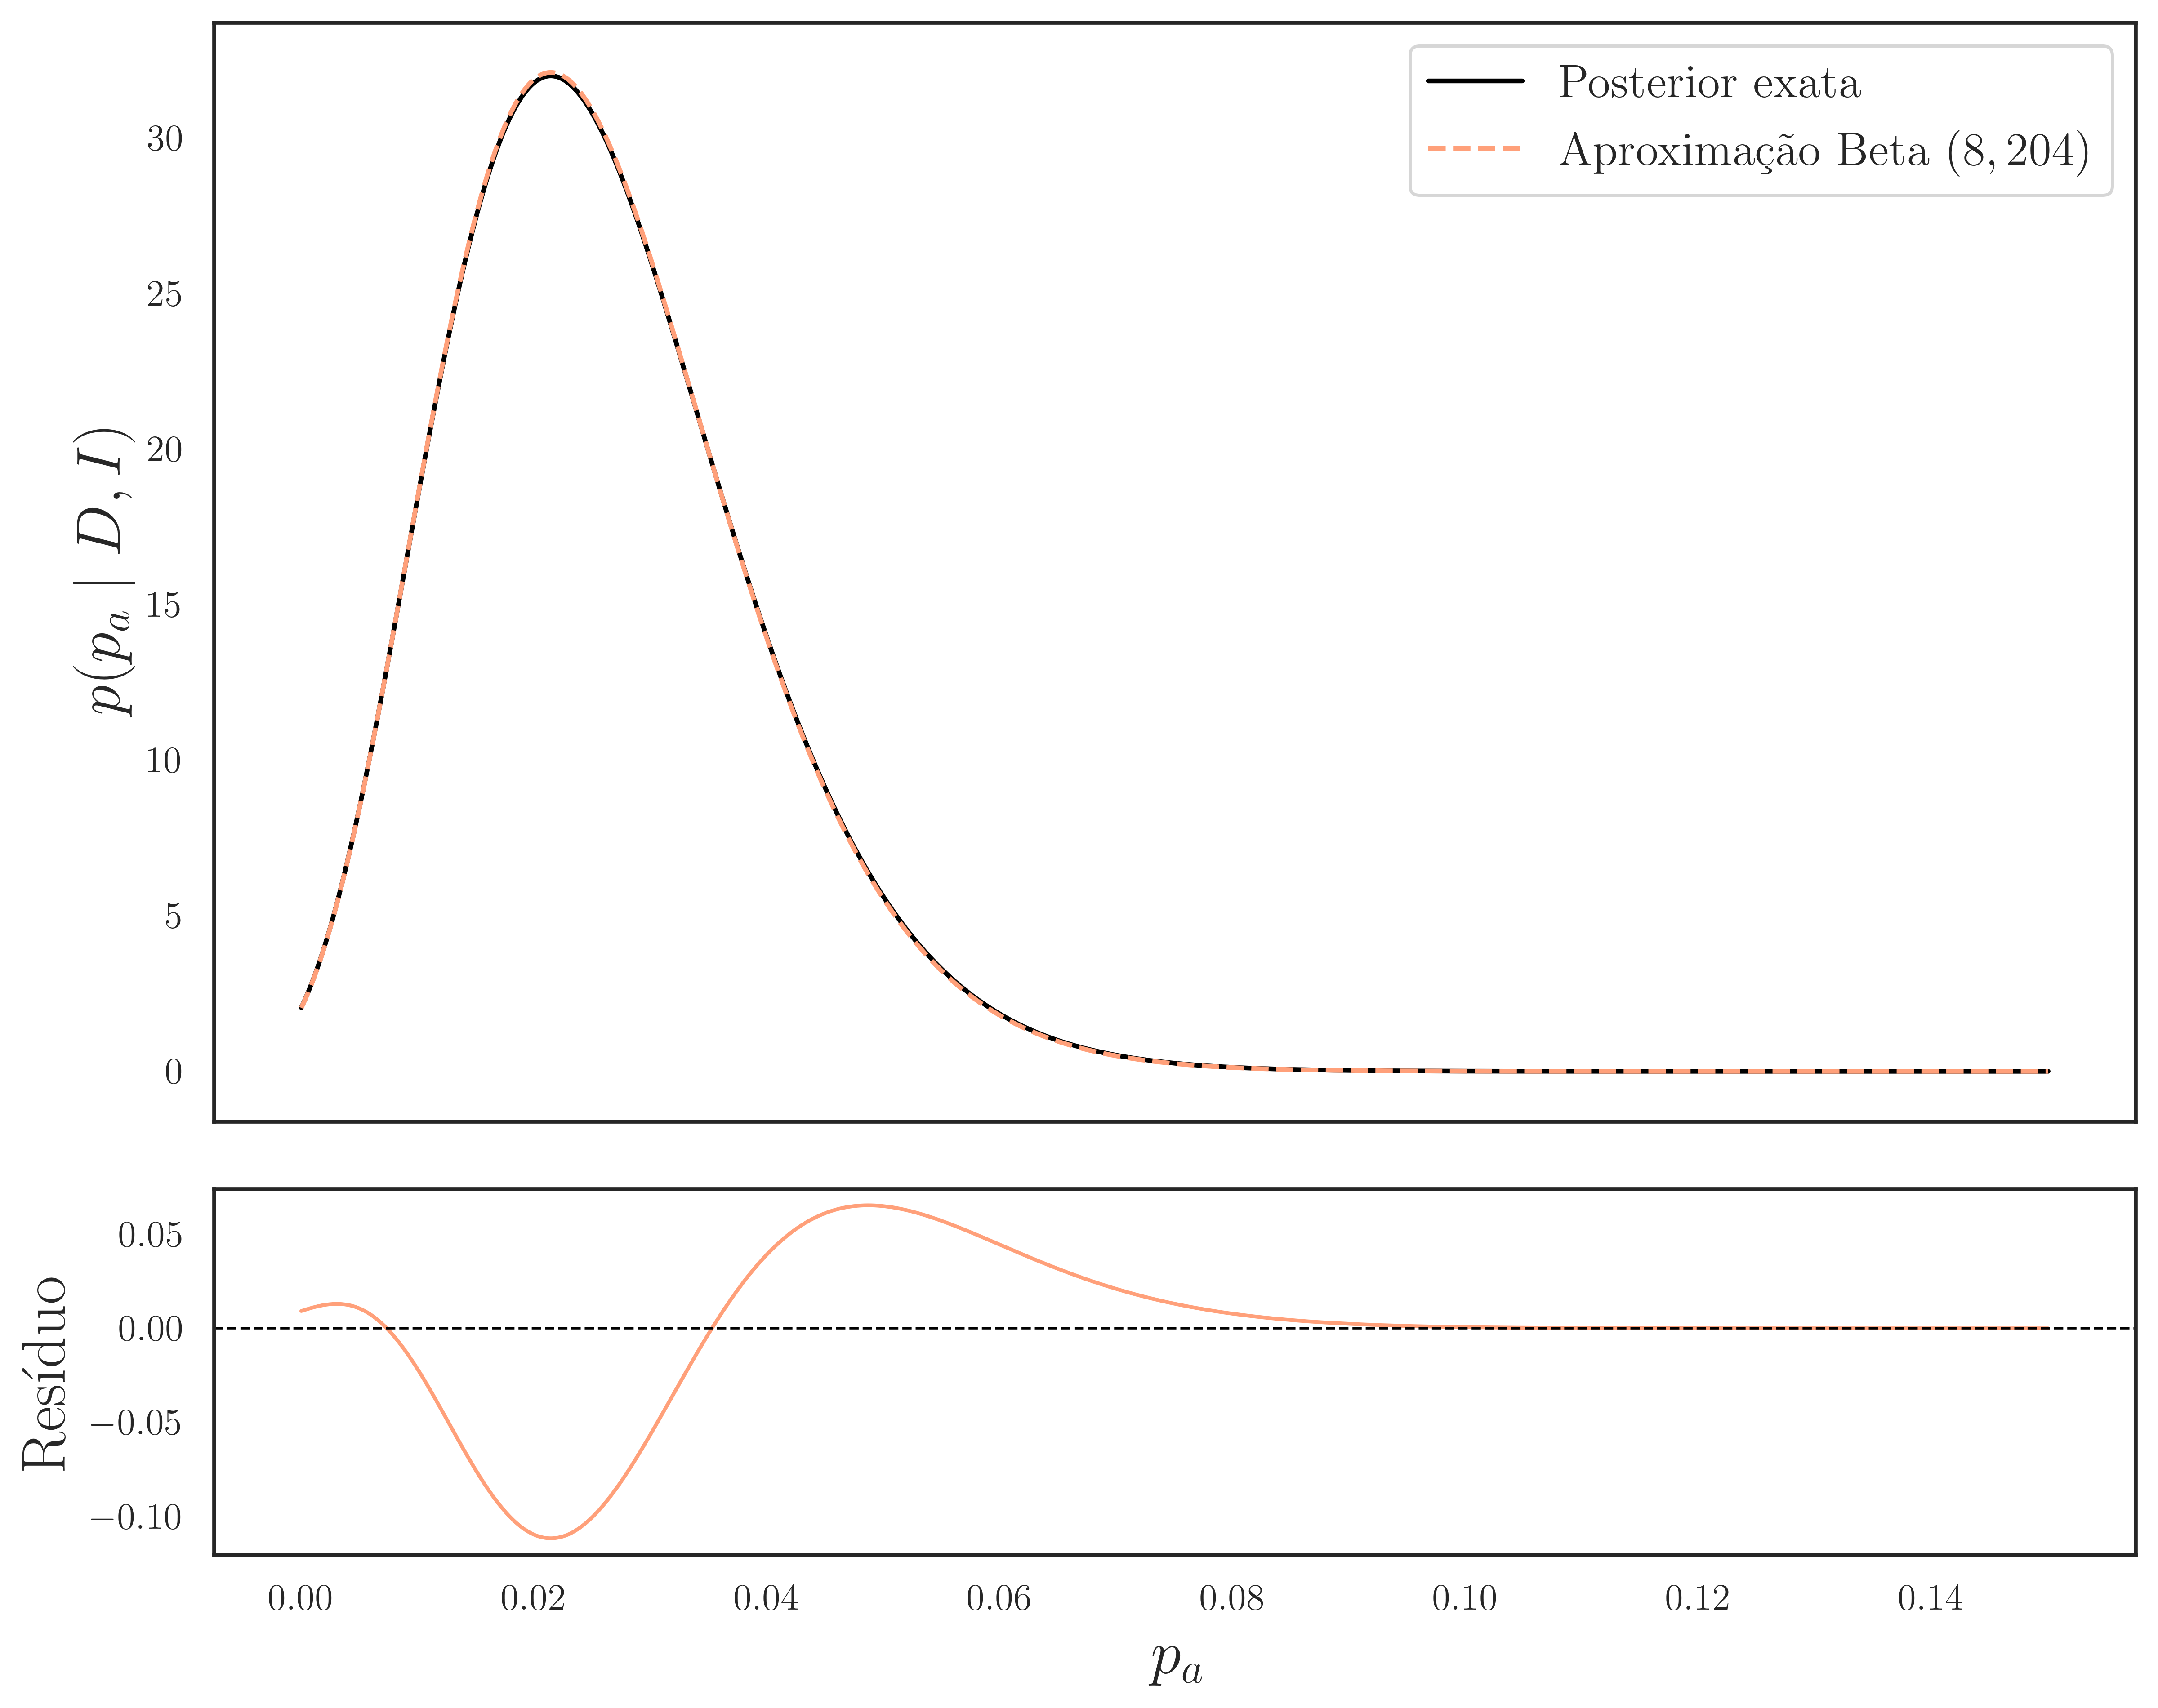

In [122]:
alpha = r + 1
beta_param = n*c - r + 1

def beta_aprox(pa):
    return beta.pdf(pa + pmin, alpha, beta_param)

norm_6b, error_6b = quad(beta_aprox, 0, 1)

def posterior_aprox(pa):
    return beta_aprox(pa) / norm_6b

pa = np.linspace(0, 0.15, 1000)

pdf_exact = posterior(pa)
pdf_aprox = posterior_aprox(pa)

residual = pdf_exact - pdf_aprox

fig, ax = plt.subplots(2, 1, figsize=(10, 8), dpi=500, sharex=True, gridspec_kw={'height_ratios': [3, 1]})

ax[0].plot(pa, pdf_exact, color='black', lw=1.5, label='Posterior exata')

ax[0].plot(pa, pdf_aprox, color=colors[2], lw=1.5, ls='--', label=r'Aproximação Beta $(8,204)$')

ax[0].set_ylabel(r'$p(p_a\mid D,I)$')
ax[0].legend()

# Resíduo
ax[1].plot(pa, residual, color=colors[2], lw=1.2)

ax[1].axhline(0, color='black', lw=0.8, ls='--')

ax[1].set_xlabel(r'$p_a$')
ax[1].set_ylabel('Resíduo')

plt.tight_layout()
plt.show()

### (c) Comportamento da aproximação em diferentes amostras

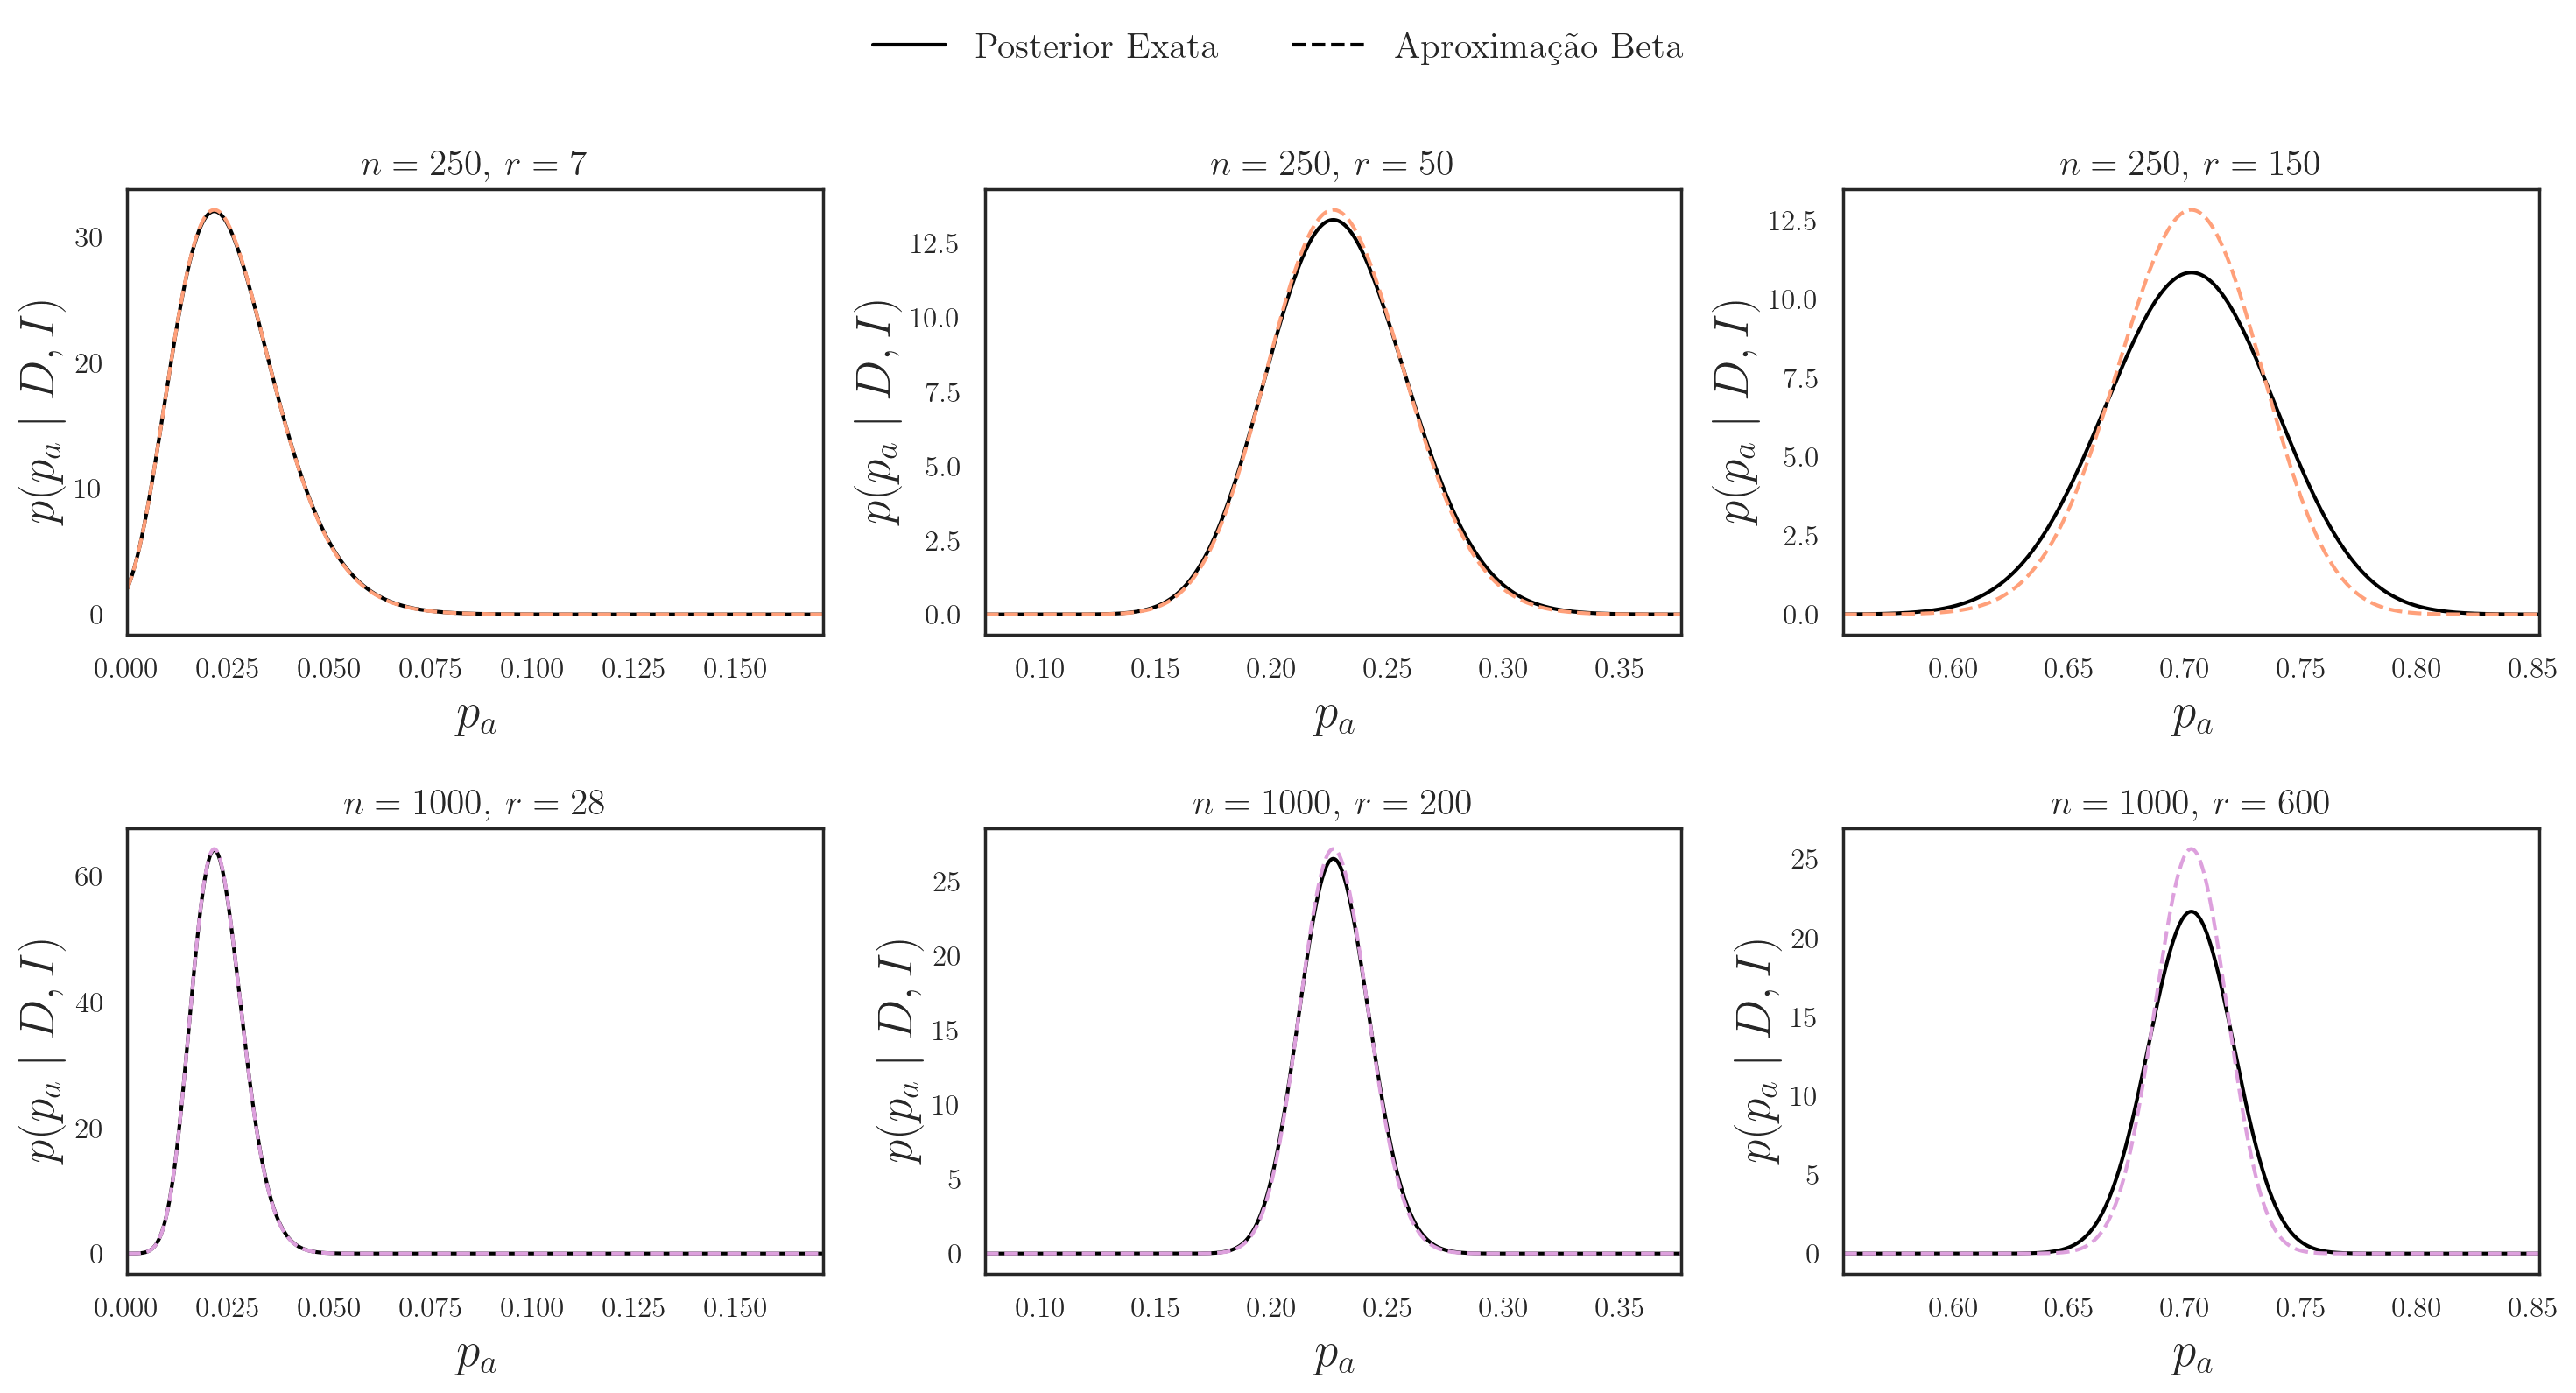

In [ ]:
cases = [(250, 7), (250, 50), (250, 150),
    (1000, 28), (1000, 200), (1000, 600)]


pa = np.linspace(0, 1, 10000)

def bin_distribution(n, r):

    alpha = r + 1
    beta_param = n*c - r + 1

    # Posterior original
    q = c*pa + FPR

    norm_exata = (beta_dist.cdf(c + FPR, r+1, n-r+1) - beta_dist.cdf(FPR, r+1, n-r+1))

    pdf_exact = (c * beta_dist.pdf(q, r+1, n-r+1) / norm_exata)

    # Posterior aproximada
    norm_aprox = (beta_dist.cdf(1, alpha, beta_param) - beta_dist.cdf(pmin, alpha, beta_param))

    pdf_aprox = (beta_dist.pdf(pa+pmin, alpha, beta_param) / norm_aprox)

    return pdf_exact, pdf_aprox

fig, ax = plt.subplots(2, 3, figsize=(15, 8), dpi=200)


for i, (n, r) in enumerate(cases):

    pdf_exact, pdf_aprox = bin_distribution(n, r)

    line = i // 3
    column = i % 3

    color = colors[2] if n == 250 else colors[3]

    ax[line, column].plot(pa, pdf_exact, color='black', lw=1.5, label='Posterior exata')

    ax[line, column].plot(pa, pdf_aprox, color=color, lw=1.5, ls='--', label='Aproximação Beta')

    ax[line, column].set_title(fr'$n={n}$, $r={r}$')

    ax[line, column].set_xlabel(r'$p_a$')
    ax[line, column].set_ylabel(r'$p(p_a\mid D,I)$')

    pa_max = (r/n - FPR)/c

    ax[line, column].set_xlim(max(0, pa_max - 0.15), min(1, pa_max + 0.15))

legenda = [Line2D([0], [0], color='black', lw=1.5, ls='-', label='Posterior Exata'), Line2D([0], [0], color='black', lw=1.5, ls='--', label='Aproximação Beta')]

fig.legend(handles=legenda, loc='upper center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=False)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


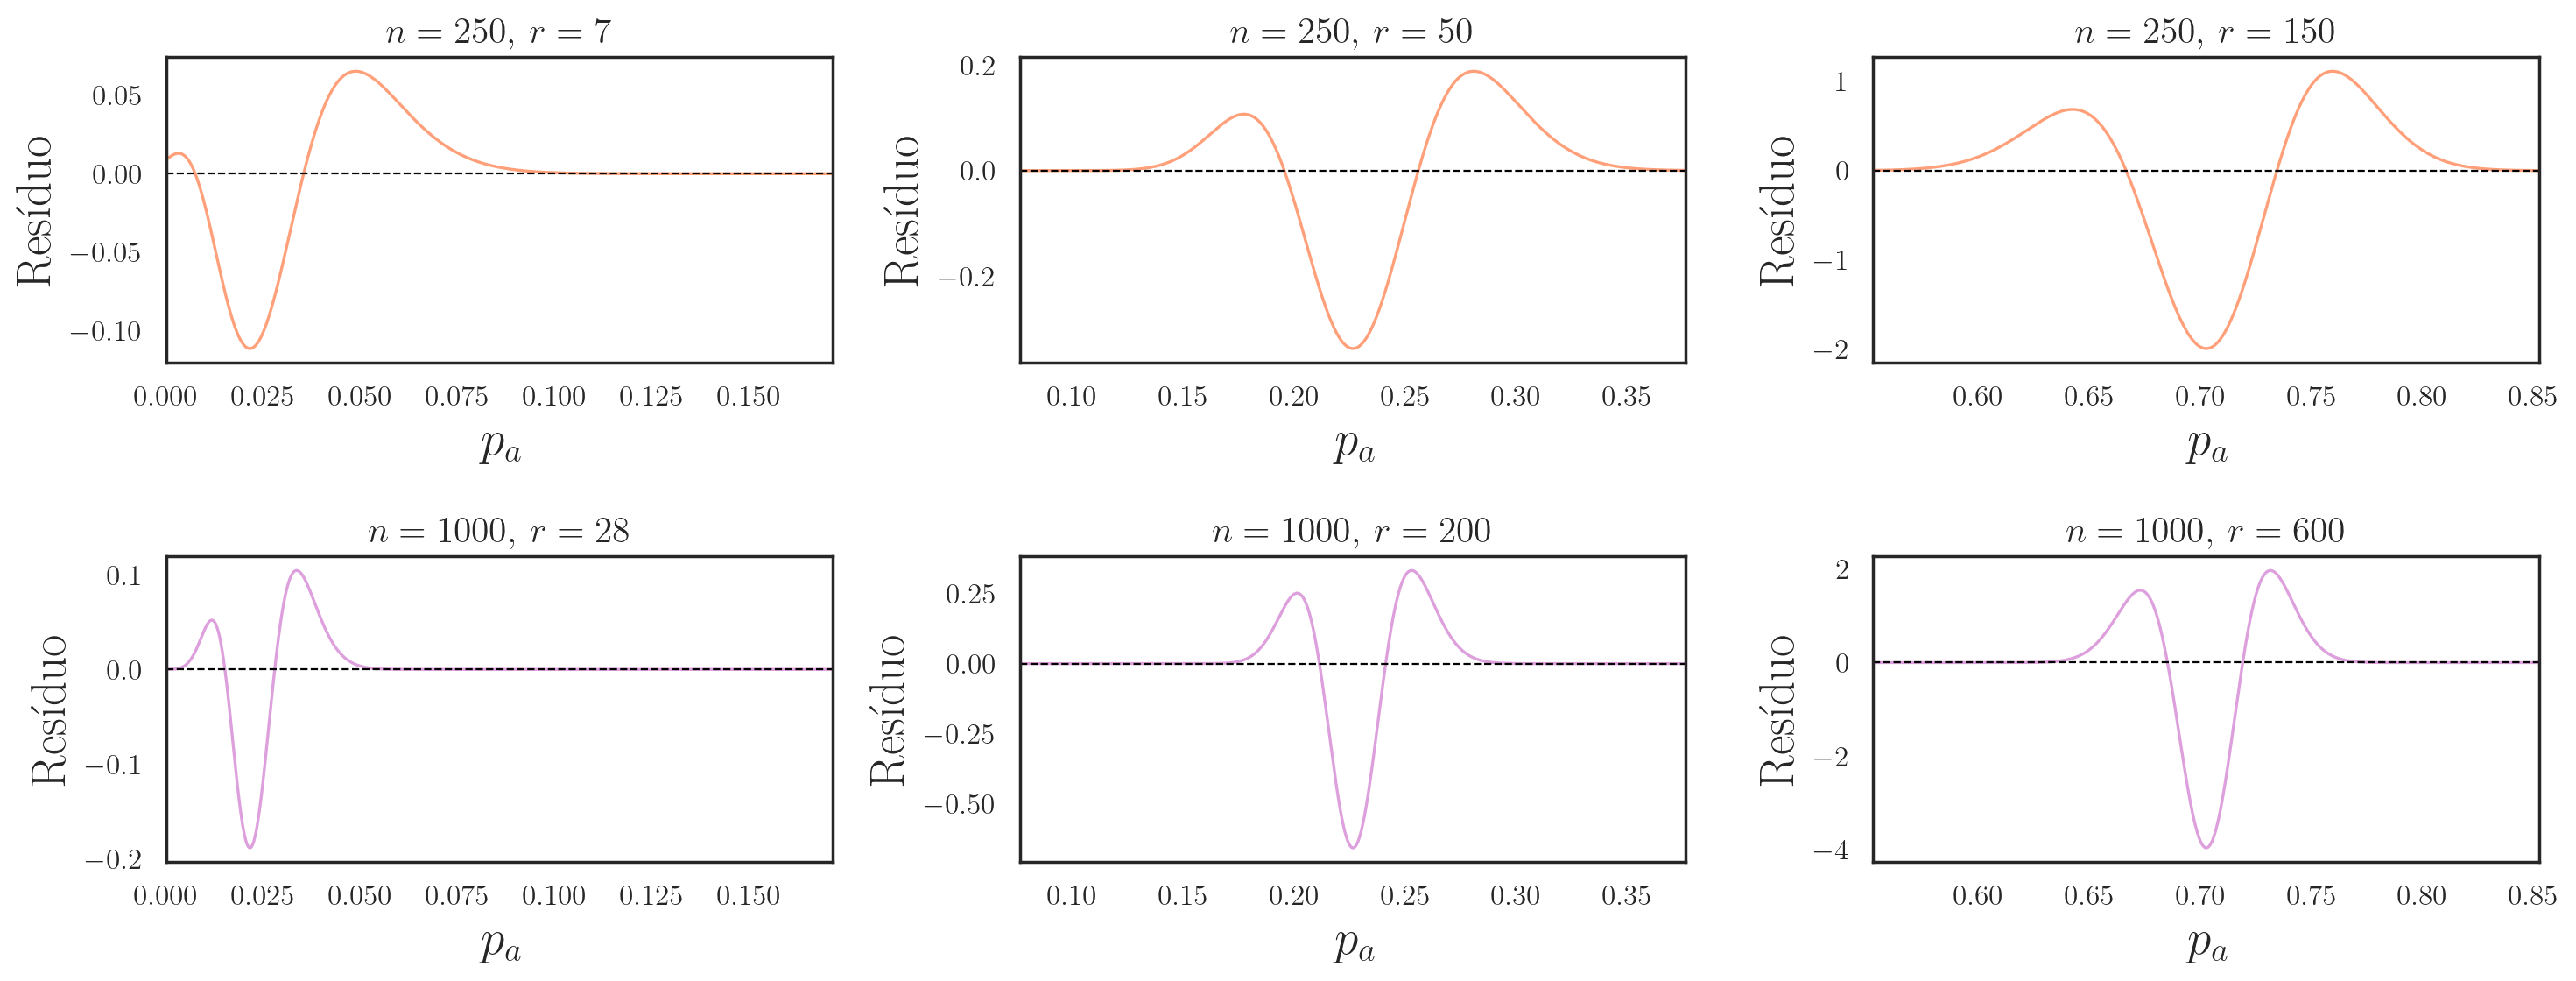

In [124]:
fig, ax = plt.subplots(2, 3, figsize=(15, 6), dpi=200)

for i, (n, r) in enumerate(cases):

    pdf_exact, pdf_aprox = bin_distribution(n, r)

    residual = pdf_exact - pdf_aprox

    line = i // 3
    column = i % 3

    cor = colors[2] if n == 250 else colors[3]

    ax[line, column].plot(pa, residual, color=cor, lw=1.2)

    ax[line, column].axhline(0, color='black', lw=0.8, ls='--')

    ax[line, column].set_title(fr'$n={n}$, $r={r}$')

    ax[line, column].set_xlabel(r'$p_a$')
    ax[line, column].set_ylabel('Resíduo')

    pa_max = (r/n - FPR)/c

    ax[line, column].set_xlim(max(0, pa_max - 0.15), min(1, pa_max + 0.15))

plt.tight_layout()
plt.show()

### (d) Combinação de duas cidades

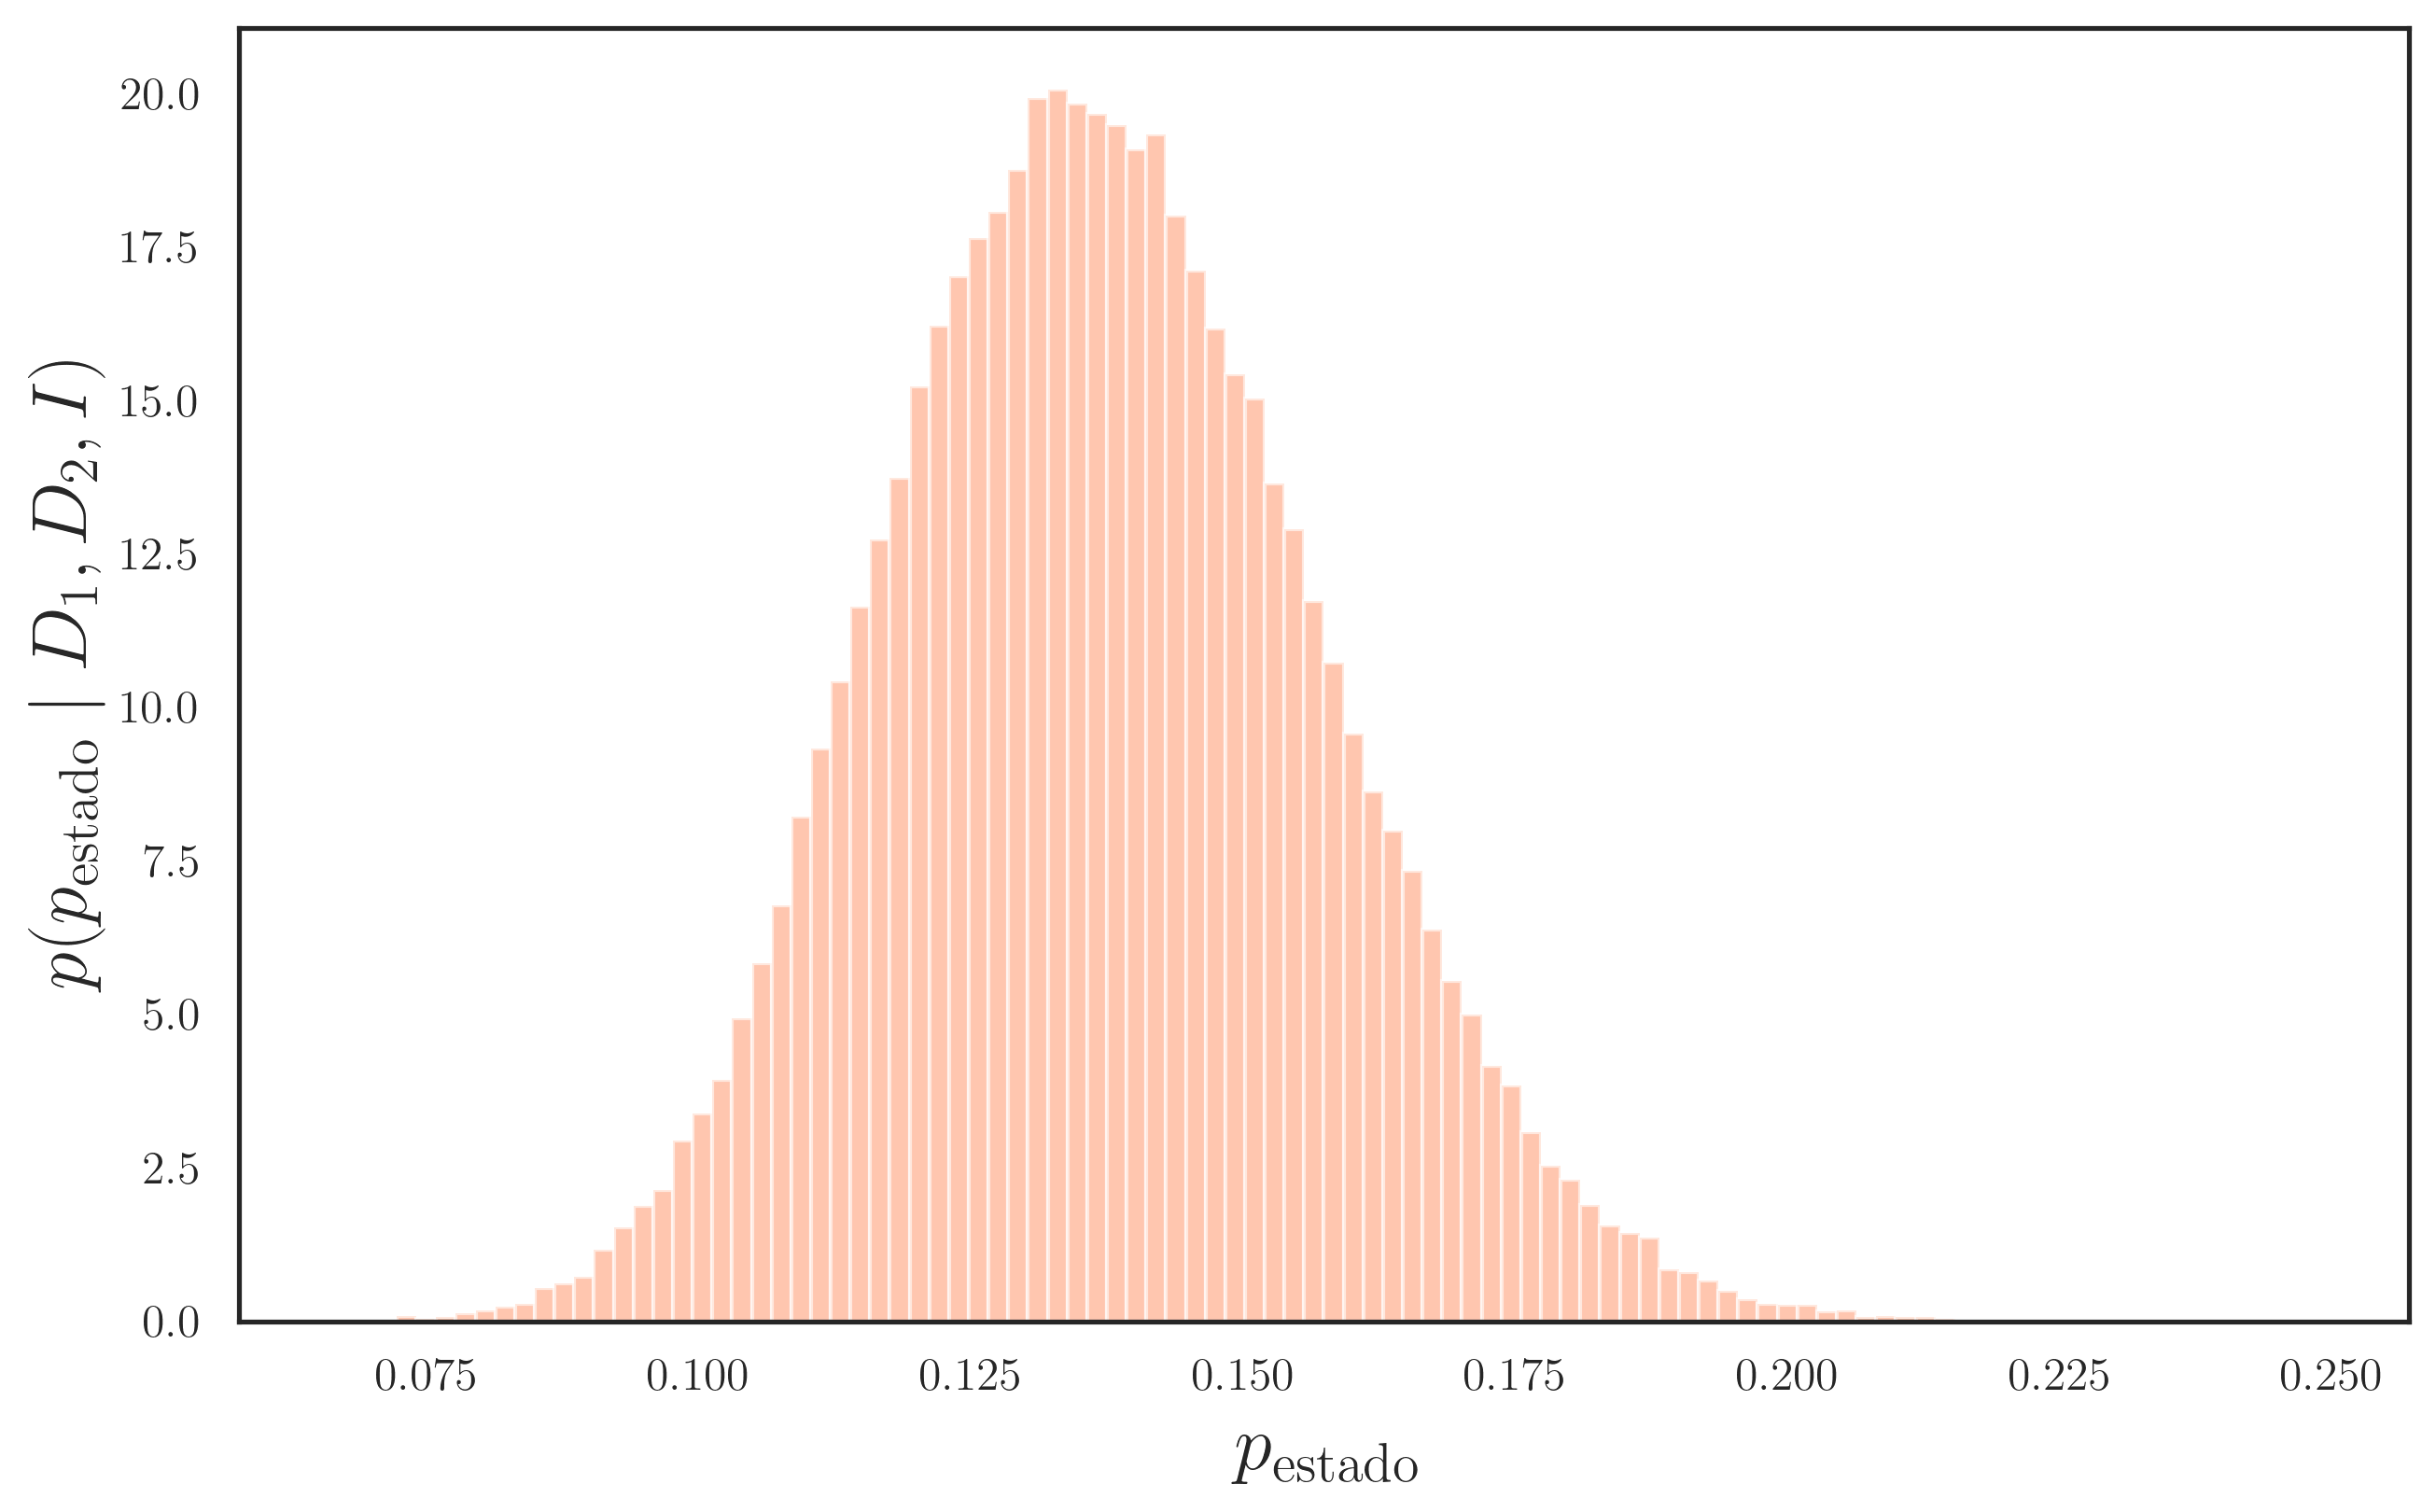

In [125]:
pop1 = 200000
pop2 = 500000

n1, r1 = 250, 7
n2, r2 = 250, 40

def posterior_city(pa, n, r):

    def likelihood(p):
        p_positive = c*p + FPR
        return comb(n, r) * p_positive**r * (1-p_positive)**(n-r)

    evidence, _ = quad(likelihood, 0, 1)

    return likelihood(pa) / evidence

pa = np.linspace(0, 1, 10000)

pdf1 = posterior_city(pa, n1, r1)
pdf2 = posterior_city(pa, n2, r2)

prob1 = pdf1 / np.sum(pdf1)
prob2 = pdf2 / np.sum(pdf2)

rng = np.random.default_rng(42)

sample_1 = rng.choice(pa, size=100000, p=prob1)
sample_2 = rng.choice(pa, size=100000, p=prob2)

amostras_estado = (
    pop1*sample_1 + pop2*sample_2
) / (pop1 + pop2)

plt.figure(figsize=(10, 6), dpi=300)

plt.hist(amostras_estado, bins=100, density=True, color=colors[2], alpha=0.6)

plt.xlabel(r'$p_{\mathrm{estado}}$')
plt.ylabel(r'$p(p_{\mathrm{estado}}\mid D_1,D_2,I)$')
plt.show()
